# Forecasting Emerging Research Topics in AI (arXiv 2013–2025)
Pipeline: arXiv metadata → SBERT embeddings → BERTopic → topic-share trends → forecasting which topics will grow.

In [1]:
# ---------------------------------------------------------------
# Setup: install libraries, fix random seeds, define paths and caching
# ---------------------------------------------------------------
!pip install -q bertopic sentence-transformers umap-learn hdbscan gensim

import os, json, random, glob, shutil
import numpy as np
import pandas as pd
from tqdm.auto import tqdm

# Fixed seed so sampling and models give the same results on every run
SEED = 42
random.seed(SEED); np.random.seed(SEED)

# Locate the arXiv metadata file inside Kaggle's input folder
RAW_JSON = glob.glob("/kaggle/input/**/arxiv-metadata-oai-snapshot.json", recursive=True)[0]

# Output folders for everything this notebook produces
OUT = "/kaggle/working/v2"
for d in ["data", "models", "figures", "results"]:
    os.makedirs(f"{OUT}/{d}", exist_ok=True)

# Caching of expensive models (embeddings, BERTopic model, topic assignments).
# True  = reuse saved models if available (development)
# False = rebuild everything from the raw arXiv file (final reproducibility run)
USE_CACHE = False

def cached_file(relpath):
    """
    Return the path of a previously saved model file (relative to OUT), or None.
    Looks in this session's output folder first, then in the output of a
    previous committed run attached via 'Add Input' (copied into OUT).
    """
    if not USE_CACHE:
        return None
    target = f"{OUT}/{relpath}"
    if os.path.exists(target):
        return target
    hits = glob.glob(f"/kaggle/input/**/v2/{relpath}", recursive=True)
    if hits:
        os.makedirs(os.path.dirname(target), exist_ok=True)
        shutil.copy(hits[0], target)
        print(f"[cache] reused {relpath} from previous run")
        return target
    return None

print(RAW_JSON)
print(os.path.exists(RAW_JSON), "| Setup OK | USE_CACHE =", USE_CACHE)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.7/154.7 kB 4.8 MB/s eta 0:00:00
/kaggle/input/datasets/Cornell-University/arxiv/arxiv-metadata-oai-snapshot.json
True | Setup OK | USE_CACHE = False


## 1. Data loading
Papers listed in cs.AI, cs.LG, cs.CL, cs.CV or stat.ML.
Year = date of the **first submitted version** (not last update).
Authors are kept for author-based trend features later.

In [2]:
# ---------------------------------------------------------------
# Step 1: Extract AI papers from the full arXiv metadata file
# ---------------------------------------------------------------
# The file has one JSON record per line (~2.8M papers). Reading it
# line by line and keeping only the fields we need is much faster and
# uses far less memory than loading everything with pandas.

AI_CATS = {"cs.AI", "cs.LG", "cs.CL", "cs.CV", "stat.ML"}

rows = []
with open(RAW_JSON) as f:
    for line in tqdm(f, desc="Scanning arXiv"):
        p = json.loads(line)
        cats = p["categories"].split()

        # Keep the paper if ANY of its categories is an AI category
        if not AI_CATS.intersection(cats):
            continue

        rows.append({
            "id": p["id"],
            "title": p["title"],
            "abstract": p["abstract"],
            "categories": p["categories"],
            "primary_cat": cats[0],                        # arXiv lists the primary category first
            "v1_created": p["versions"][0]["created"],     # date of FIRST submission (true publication date)
            "n_versions": len(p["versions"]),              # number of revisions
            "authors": ["{}, {}".format(a[0], a[1]).strip(", ")   # "Last, First" for author tracking
                        for a in p["authors_parsed"]],
            "comments": p.get("comments") or "",           # often mentions venue, e.g. "Accepted at NeurIPS"
        })

df = pd.DataFrame(rows)

# Convert the v1 timestamp (e.g. "Mon, 2 Apr 2007 19:18:42 GMT") to a date and year.
# We deliberately do NOT use update_date: it is the date of the latest revision,
# which would push older papers into later years.
df["date"] = pd.to_datetime(df["v1_created"], format="%a, %d %b %Y %H:%M:%S GMT", errors="coerce")
df["year"] = df["date"].dt.year

# Flag papers whose primary category is AI (vs. only cross-listed into AI)
df["is_primary_ai"] = df["primary_cat"].isin(AI_CATS)

print("AI papers (any listing):", len(df))
print("Primary category is AI:", df["is_primary_ai"].sum())
print("Unparsed dates:", df["date"].isna().sum())
print("Latest paper date in snapshot:", df["date"].max())

Scanning arXiv: 0it [00:00, ?it/s]

AI papers (any listing): 619815
Primary category is AI: 470890
Unparsed dates: 0
Latest paper date in snapshot: 2026-10-08 17:59:58


In [3]:
# ---------------------------------------------------------------
# Step 2: Clean text, remove unusable papers, save the dataset
# ---------------------------------------------------------------
import re

def clean(t):
    """Replace newlines and repeated spaces with a single space."""
    return re.sub(r"\s+", " ", str(t)).strip()

df["title"]    = df["title"].map(clean)
df["abstract"] = df["abstract"].map(clean)

n0 = len(df)
df = df.drop_duplicates("id")                              # safety check for repeated records
df = df[df["abstract"].str.split().str.len() >= 30]        # drop very short or withdrawn abstracts
df = df[(df["year"] >= 2013) & (df["year"] <= 2025)]       # study period

# Combined text used for embeddings. SBERT works on natural text,
# so we do NOT lowercase or remove stopwords here.
df["text"] = df["title"] + ". " + df["abstract"]

print(f"Kept {len(df):,} of {n0:,} papers")

# Papers per year, split by whether the primary category is AI
print(pd.crosstab(df["year"], df["is_primary_ai"], margins=True))

# Parquet is faster and smaller than pickle, and readable from other tools
df.to_parquet(f"{OUT}/data/arxiv_ai_clean.parquet", index=False)
print("Saved.")

Kept 500,320 of 619,815 papers
is_primary_ai   False    True     All
year                                 
2013              910    3359    4269
2014             1079    3450    4529
2015             1318    4977    6295
2016             1960    7940    9900
2017             2623   12038   14661
2018             4184   18313   22497
2019             8194   24367   32561
2020            12270   31399   43669
2021            12272   36004   48276
2022            14152   39156   53308
2023            16138   50752   66890
2024            21063   65571   86634
2025            25361   81470  106831
All            121524  378796  500320
Saved.


## 2. Dataset decisions
- **Primary-AI papers only**: cross-listed papers from other fields are excluded so topics reflect core AI research.
- **2013–2025**: the snapshot extends to Oct 2026, so every year in this range is complete.
- **Balanced fitting sample**: the topic model is fitted on an equal number of papers per year, then applied to all papers, so early years are not drowned out by the much larger recent years.

Papers used in the study: 378,796


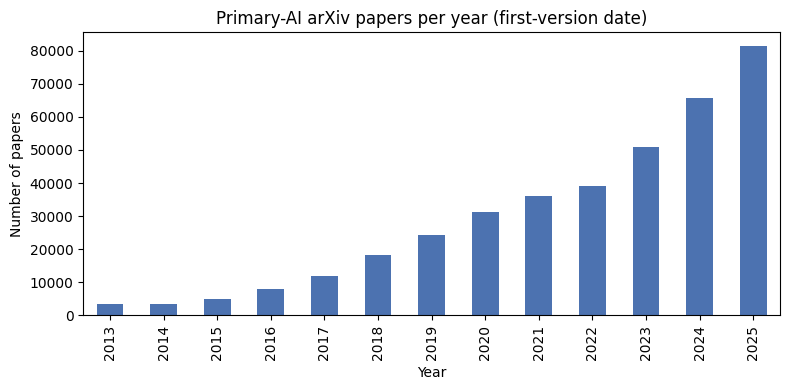

In [4]:
# ---------------------------------------------------------------
# Step 3: Keep primary-AI papers and summarise the dataset
# ---------------------------------------------------------------
import matplotlib.pyplot as plt

df = df[df["is_primary_ai"]].reset_index(drop=True)
print(f"Papers used in the study: {len(df):,}")

# Papers per year (Figure 1 of the report)
counts = df.groupby("year").size()
fig, ax = plt.subplots(figsize=(8, 4))
counts.plot.bar(ax=ax, color="#4C72B0")
ax.set_title("Primary-AI arXiv papers per year (first-version date)")
ax.set_xlabel("Year"); ax.set_ylabel("Number of papers")
plt.tight_layout()
plt.savefig(f"{OUT}/figures/fig1_papers_per_year.png", dpi=200)
plt.show()

df.to_parquet(f"{OUT}/data/arxiv_ai_primary.parquet", index=False)

In [5]:
# ---------------------------------------------------------------
# Step 4: Year-balanced sample for fitting the topic model
# ---------------------------------------------------------------
# The smallest year (2013) has 3,359 primary-AI papers, so 3,000 per year
# lets every year contribute equally. Topics are later assigned to ALL papers.
N_PER_YEAR = 3000

fit_df = (df.groupby("year")
            .sample(n=N_PER_YEAR, random_state=SEED)
            .reset_index(drop=True))

print(fit_df["year"].value_counts().sort_index())
print(f"Fitting sample size: {len(fit_df):,}")

# Save the sampled IDs so the exact sample can be reproduced
fit_df[["id"]].to_csv(f"{OUT}/data/fit_sample_ids.csv", index=False)

year
2013    3000
2014    3000
2015    3000
2016    3000
2017    3000
2018    3000
2019    3000
2020    3000
2021    3000
2022    3000
2023    3000
2024    3000
2025    3000
Name: count, dtype: int64
Fitting sample size: 39,000


## 3. Choosing the embedding model
We compare three sentence-embedding models on a year-balanced subsample (400 papers/year) using:
- **kNN category accuracy**: how well embeddings alone recover a paper's arXiv category
- **NPMI coherence**: whether each topic's top words co-occur in real papers
- **Topic diversity**: share of unique words across topics' top-10 lists
- **Outlier rate** and **encoding time**

All models use identical UMAP/HDBSCAN settings so only the embeddings differ.

In [6]:
# ---------------------------------------------------------------
# Step 5a: Helper to measure topic quality (coherence + diversity)
# ---------------------------------------------------------------
from gensim.corpora import Dictionary
from gensim.models.coherencemodel import CoherenceModel

def topic_quality(tm, docs, topics, top_n=10):
    """Return number of topics, outlier rate, NPMI coherence and topic diversity."""
    # Tokenise documents the same way the topic model's vectorizer does
    analyzer = tm.vectorizer_model.build_analyzer()
    tokens = [analyzer(d) for d in docs]
    dictionary = Dictionary(tokens)

    # Top-n words of every real topic (-1 = outliers, skipped)
    topic_words = [[w for w, _ in tm.get_topic(t)[:top_n] if w in dictionary.token2id]
                   for t in sorted(set(topics)) if t != -1]
    topic_words = [tw for tw in topic_words if len(tw) >= 2]

    # NPMI coherence: ranges -1..1, higher = top words appear together more often
    npmi = CoherenceModel(topics=topic_words, texts=tokens, dictionary=dictionary,
                          coherence="c_npmi", processes=1).get_coherence()

    # Diversity: 1.0 means no word is shared between topics
    all_words = [w for tw in topic_words for w in tw]
    diversity = len(set(all_words)) / len(all_words)

    outlier_rate = float(np.mean(np.array(topics) == -1))
    return len(topic_words), outlier_rate, npmi, diversity

In [7]:
# ---------------------------------------------------------------
# Step 5b: Compare embedding models on the same subsample
# ---------------------------------------------------------------
import time, torch
from sentence_transformers import SentenceTransformer
from bertopic import BERTopic
from umap import UMAP
from hdbscan import HDBSCAN
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_score

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

# 400 papers per year, drawn from the balanced fitting sample
cmp_df = fit_df.groupby("year").sample(n=400, random_state=SEED).reset_index(drop=True)
docs = cmp_df["text"].tolist()

CANDIDATES = {
    "MiniLM-L6 (384d)":  "sentence-transformers/all-MiniLM-L6-v2",   # small and fast
    "MPNet-base (768d)": "sentence-transformers/all-mpnet-base-v2",  # stronger general model
    "SPECTER (768d)":    "sentence-transformers/allenai-specter",    # trained on scientific papers
}

results = []
for name, path in CANDIDATES.items():
    print(f"\n=== {name} ===")
    model = SentenceTransformer(path, device=device)

    # 1) Encode and time it
    t0 = time.time()
    emb = model.encode(docs, batch_size=64, show_progress_bar=True, normalize_embeddings=True)
    enc_time = time.time() - t0

    # 2) Embedding quality: can neighbours in embedding space predict the arXiv category?
    knn = KNeighborsClassifier(n_neighbors=10, metric="cosine")
    knn_acc = cross_val_score(knn, emb, cmp_df["primary_cat"], cv=5).mean()

    # 3) Topic quality: identical BERTopic settings for every model
    tm = BERTopic(
        umap_model=UMAP(n_neighbors=15, n_components=5, min_dist=0.0,
                        metric="cosine", random_state=SEED),
        hdbscan_model=HDBSCAN(min_cluster_size=30, min_samples=10, prediction_data=True),
        vectorizer_model=CountVectorizer(stop_words="english", min_df=5),
    )
    topics, _ = tm.fit_transform(docs, emb)
    n_topics, outliers, npmi, diversity = topic_quality(tm, docs, topics)

    results.append({"model": name, "encode_sec": round(enc_time, 1),
                    "knn_category_acc": round(knn_acc, 3), "n_topics": n_topics,
                    "outlier_rate": round(outliers, 3), "npmi": round(npmi, 3),
                    "diversity": round(diversity, 3)})

    del model; torch.cuda.empty_cache()   # free GPU memory before the next model

cmp_results = pd.DataFrame(results)
cmp_results.to_csv(f"{OUT}/results/table1_embedding_comparison.csv", index=False)
cmp_results

Device: cuda

=== MiniLM-L6 (384d) ===


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

...

tokenizer.json:   0%|          | 0.00/462k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/82 [00:00<?, ?it/s]

,model,encode_sec,knn_category_acc,n_topics,outlier_rate,npmi,diversity
0,MiniLM-L6 (384d),11.9,0.773,46,0.328,0.097,0.731
1,MPNet-base (768d),86.9,0.769,46,0.269,0.078,0.713
2,SPECTER (768d),83.2,0.768,33,0.260,0.089,0.703


**Decision:** all-MiniLM-L6-v2 is selected. It matched the larger models on category accuracy (0.773 vs 0.769/0.768), had the highest coherence (NPMI 0.097) and diversity (0.731), and encoded ~8× faster, which matters for embedding the full corpus of ~379k papers.

## 4. Embedding the full corpus

In [8]:
# ---------------------------------------------------------------
# Step 6: Encode ALL primary-AI papers with the chosen model
# ---------------------------------------------------------------
# Embeddings are computed once and reused (see USE_CACHE in the setup cell).
EMB_PATH = f"{OUT}/data/embeddings_minilm.npy"

if cached_file("data/embeddings_minilm.npy"):
    embeddings = np.load(EMB_PATH)
    print("[cache] loaded embeddings")
else:
    encoder = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2", device=device)
    embeddings = encoder.encode(
        df["text"].tolist(),
        batch_size=256,
        show_progress_bar=True,
        normalize_embeddings=True,   # unit length, so cosine similarity = dot product
    ).astype(np.float16)             # half precision halves file size with no practical loss
    np.save(EMB_PATH, embeddings)
    del encoder; torch.cuda.empty_cache()

# Row i of `embeddings` corresponds to row i of `df`; this check catches a mismatched cache
assert len(embeddings) == len(df), "Embeddings and dataframe are misaligned!"
df[["id"]].to_csv(f"{OUT}/data/embedding_row_ids.csv", index=False)
print("Embeddings shape:", embeddings.shape)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Batches:   0%|          | 0/1480 [00:00<?, ?it/s]

Embeddings shape: (378796, 384)


## 5. Topic model: cluster-size sensitivity
HDBSCAN's `min_cluster_size` controls how many topics are found. We fit BERTopic on the balanced sample (39,000 papers) with four values and compare number of topics, outlier rate, NPMI coherence and diversity. UMAP is computed once and shared, so only the clustering step varies.

In [9]:
# ---------------------------------------------------------------
# Step 7: Sensitivity analysis for HDBSCAN min_cluster_size
# ---------------------------------------------------------------
from bertopic.dimensionality import BaseDimensionalityReduction

# Pick the embeddings of the 39k balanced-sample papers (matched by paper id)
row_of_id = pd.Series(np.arange(len(df)), index=df["id"])
fit_idx   = row_of_id.loc[fit_df["id"]].to_numpy()
fit_emb   = embeddings[fit_idx].astype(np.float32)
fit_docs  = fit_df["text"].tolist()

# Reduce to 5 dimensions ONCE (same settings as the model comparison)
t0 = time.time()
umap_fit = UMAP(n_neighbors=15, n_components=5, min_dist=0.0,
                metric="cosine", random_state=SEED)
fit_reduced = umap_fit.fit_transform(fit_emb)
print(f"UMAP done in {time.time()-t0:.0f}s")

# Fixed 10k-document subset used as the reference corpus for coherence (for speed)
rng = np.random.default_rng(SEED)
coh_docs = [fit_docs[i] for i in rng.choice(len(fit_docs), 10_000, replace=False)]

sweep = []
for mcs in [50, 100, 150, 200]:
    t0 = time.time()
    tm = BERTopic(
        umap_model=BaseDimensionalityReduction(),   # skip UMAP: we pass reduced vectors directly
        hdbscan_model=HDBSCAN(min_cluster_size=mcs, min_samples=10, prediction_data=True),
        vectorizer_model=CountVectorizer(stop_words="english", min_df=10),
    )
    topics, _ = tm.fit_transform(fit_docs, fit_reduced)

    n_topics, _, npmi, diversity = topic_quality(tm, coh_docs, topics)
    outliers = float(np.mean(np.array(topics) == -1))

    sweep.append({"min_cluster_size": mcs, "n_topics": n_topics,
                  "outlier_rate": round(outliers, 3), "npmi": round(npmi, 3),
                  "diversity": round(diversity, 3), "seconds": round(time.time()-t0)})
    print(sweep[-1])

sweep_df = pd.DataFrame(sweep)
sweep_df.to_csv(f"{OUT}/results/table2_cluster_size_sensitivity.csv", index=False)
sweep_df

UMAP done in 43s
{'min_cluster_size': 50, 'n_topics': 143, 'outlier_rate': 0.347, 'npmi': np.float64(0.086), 'diversity': 0.62, 'seconds': 30}
{'min_cluster_size': 100, 'n_topics': 85, 'outlier_rate': 0.325, 'npmi': np.float64(0.112), 'diversity': 0.683, 'seconds': 26}
{'min_cluster_size': 150, 'n_topics': 61, 'outlier_rate': 0.312, 'npmi': np.float64(0.113), 'diversity': 0.719, 'seconds': 24}
{'min_cluster_size': 200, 'n_topics': 50, 'outlier_rate': 0.3, 'npmi': np.float64(0.108), 'diversity': 0.722, 'seconds': 24}


,min_cluster_size,n_topics,outlier_rate,npmi,diversity,seconds
0,50,143,0.347,0.086,0.620,30
1,100,85,0.325,0.112,0.683,26
2,150,61,0.312,0.113,0.719,24
3,200,50,0.300,0.108,0.722,24


**Decision:** `min_cluster_size = 100`. Coherence plateaus from 100 upward (NPMI 0.112 vs 0.113 at 150), and 100 gives the most granular topic set (85 topics) at that plateau.

## 6. Final topic model

In [10]:
# ---------------------------------------------------------------
# Step 8a: Fit the final BERTopic model on the balanced sample
# ---------------------------------------------------------------
from bertopic.representation import KeyBERTInspired

MIN_CLUSTER_SIZE = 100

topic_model = BERTopic(
    embedding_model="sentence-transformers/all-MiniLM-L6-v2",   # needed by KeyBERTInspired to embed keywords
    umap_model=UMAP(n_neighbors=15, n_components=5, min_dist=0.0,
                    metric="cosine", random_state=SEED),
    hdbscan_model=HDBSCAN(min_cluster_size=MIN_CLUSTER_SIZE, min_samples=10,
                          prediction_data=True),
    vectorizer_model=CountVectorizer(stop_words="english", min_df=10),
    # Main keywords stay c-TF-IDF (used for metrics); KeyBERT keywords are an extra, more readable label
    representation_model={"KeyBERT": KeyBERTInspired()},
    verbose=True,
)

fit_topics, _ = topic_model.fit_transform(fit_docs, fit_emb)
fit_topics = np.array(fit_topics)
print(f"Topics: {len(set(fit_topics)) - 1}, outlier rate: {np.mean(fit_topics == -1):.3f}")

# How many outliers would be reassigned at different similarity thresholds?
# A paper is moved to its closest topic only if cosine similarity >= threshold.
for th in [0.2, 0.3, 0.4, 0.5]:
    new_t = np.array(topic_model.reduce_outliers(fit_docs, fit_topics, strategy="embeddings",
                                                 embeddings=fit_emb, threshold=th))
    print(f"threshold {th}: outlier rate {np.mean(new_t == -1):.3f}")

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

2026-10-17 02:35:37,355 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm
2026-10-17 02:36:19,343 - BERTopic - Dimensionality - Completed ✓
2026-10-17 02:36:19,345 - BERTopic - Cluster - Start clustering the reduced embeddings
2026-10-17 02:36:20,875 - BERTopic - Cluster - Completed ✓
2026-10-17 02:36:20,887 - BERTopic - Representation - Fine-tuning topics using representation models.
2026-10-17 02:36:29,746 - BERTopic - Representation - Completed ✓


Topics: 85, outlier rate: 0.325
threshold 0.2: outlier rate 0.000
threshold 0.3: outlier rate 0.001
threshold 0.4: outlier rate 0.006
threshold 0.5: outlier rate 0.029


In [11]:
# ---------------------------------------------------------------
# Step 8b: Choose the outlier-reduction threshold by measuring coherence
# ---------------------------------------------------------------
# For each threshold: reassign outliers, recompute topic keywords (c-TF-IDF),
# then measure coherence/diversity. A good threshold lowers the outlier rate
# without making topics less coherent.
rows = []
for th in [None, 0.5, 0.55, 0.6, 0.65]:
    if th is None:
        t = fit_topics                                   # no reduction (baseline)
    else:
        t = np.array(topic_model.reduce_outliers(fit_docs, fit_topics, strategy="embeddings",
                                                 embeddings=fit_emb, threshold=th))

    # Recompute topic keywords with the new assignments
    topic_model.update_topics(fit_docs, topics=t.tolist(),
                              vectorizer_model=CountVectorizer(stop_words="english", min_df=10))
    n_topics, _, npmi, diversity = topic_quality(topic_model, coh_docs, t)

    rows.append({"threshold": "none" if th is None else th,
                 "outlier_rate": round(float(np.mean(t == -1)), 3),
                 "npmi": round(npmi, 3), "diversity": round(diversity, 3)})
    print(rows[-1])

outlier_df = pd.DataFrame(rows)
outlier_df.to_csv(f"{OUT}/results/table3_outlier_threshold.csv", index=False)
outlier_df

2026-10-17 02:36:33,791 - BERTopic - WARNING: Using a custom list of topic assignments may lead to errors if topic reduction techniques are used afterwards. Make sure that manually assigning topics is the last step in the pipeline.Note that topic embeddings will also be created through weightedc-TF-IDF embeddings instead of centroid embeddings.


{'threshold': 'none', 'outlier_rate': 0.325, 'npmi': np.float64(0.121), 'diversity': 0.693}


2026-10-17 02:36:55,703 - BERTopic - WARNING: Using a custom list of topic assignments may lead to errors if topic reduction techniques are used afterwards. Make sure that manually assigning topics is the last step in the pipeline.Note that topic embeddings will also be created through weightedc-TF-IDF embeddings instead of centroid embeddings.


{'threshold': 0.5, 'outlier_rate': 0.029, 'npmi': np.float64(0.133), 'diversity': 0.651}


2026-10-17 02:37:18,012 - BERTopic - WARNING: Using a custom list of topic assignments may lead to errors if topic reduction techniques are used afterwards. Make sure that manually assigning topics is the last step in the pipeline.Note that topic embeddings will also be created through weightedc-TF-IDF embeddings instead of centroid embeddings.


...

2026-10-17 02:37:40,241 - BERTopic - WARNING: Using a custom list of topic assignments may lead to errors if topic reduction techniques are used afterwards. Make sure that manually assigning topics is the last step in the pipeline.Note that topic embeddings will also be created through weightedc-TF-IDF embeddings instead of centroid embeddings.


{'threshold': 0.6, 'outlier_rate': 0.113, 'npmi': np.float64(0.13), 'diversity': 0.66}


2026-10-17 02:38:02,414 - BERTopic - WARNING: Using a custom list of topic assignments may lead to errors if topic reduction techniques are used afterwards. Make sure that manually assigning topics is the last step in the pipeline.Note that topic embeddings will also be created through weightedc-TF-IDF embeddings instead of centroid embeddings.


{'threshold': 0.65, 'outlier_rate': 0.187, 'npmi': np.float64(0.128), 'diversity': 0.678}


,threshold,outlier_rate,npmi,diversity
0,none,0.325,0.121,0.693
1,0.5,0.029,0.133,0.651
2,0.55,0.060,0.133,0.655
3,0.6,0.113,0.130,0.660
4,0.65,0.187,0.128,0.678


**Decision:** outlier threshold = 0.6. Reassigning outliers *raised* coherence (NPMI 0.121 → 0.130); coherence is flat between 0.5 and 0.6, so we use the most conservative value on that plateau, cutting outliers from 32.5% to 11.3% without forcing ambiguous papers into topics.

## 7. Assigning topics to the full corpus

In [12]:
# ---------------------------------------------------------------
# Step 9: Final model and topic assignment for ALL papers
# ---------------------------------------------------------------
# The fitted BERTopic model and topic assignments are created once and reused.
# Pickle format keeps UMAP + HDBSCAN inside the model, which is needed to
# assign topics to new (2026) papers later.
OUTLIER_TH = 0.6
MODEL_PATH = f"{OUT}/models/bertopic_final.pkl"

if (cached_file("models/bertopic_final.pkl") and cached_file("data/paper_topics.parquet")
        and cached_file("data/fit_topics.npz")):
    topic_model = BERTopic.load(MODEL_PATH)
    pt = pd.read_parquet(f"{OUT}/data/paper_topics.parquet")
    assert (pt["id"].to_numpy() == df["id"].to_numpy()).all(), "Cached topics do not match papers!"
    df["topic"] = pt["topic"].to_numpy()
    z = np.load(f"{OUT}/data/fit_topics.npz")
    fit_topics, fit_topics_red = z["fit_topics"], z["fit_topics_red"]
    print("[cache] loaded final topic model and topic assignments")
else:
    # 1) Fit from scratch (deterministic: same 85 topics)
    topic_model = BERTopic(
        embedding_model="sentence-transformers/all-MiniLM-L6-v2",
        umap_model=UMAP(n_neighbors=15, n_components=5, min_dist=0.0,
                        metric="cosine", random_state=SEED),
        hdbscan_model=HDBSCAN(min_cluster_size=MIN_CLUSTER_SIZE, min_samples=10,
                              prediction_data=True),
        vectorizer_model=CountVectorizer(stop_words="english", min_df=10),
        verbose=True,
    )
    fit_topics, _ = topic_model.fit_transform(fit_docs, fit_emb)
    fit_topics = np.array(fit_topics)

    # 2) Assign every paper in the corpus to a topic using its stored embedding
    all_docs = df["text"].tolist()
    all_emb  = embeddings.astype(np.float32)
    all_topics, _ = topic_model.transform(all_docs, all_emb)
    all_topics = np.array(all_topics)
    print(f"Full corpus outlier rate before reduction: {np.mean(all_topics == -1):.3f}")

    # 3) Reassign outliers whose closest topic has cosine similarity >= 0.6
    all_topics = np.array(topic_model.reduce_outliers(all_docs, all_topics, strategy="embeddings",
                                                      embeddings=all_emb, threshold=OUTLIER_TH))
    df["topic"] = all_topics

    # 4) LAST step (as BERTopic recommends): final keywords + readable KeyBERT labels
    fit_topics_red = np.array(topic_model.reduce_outliers(fit_docs, fit_topics, strategy="embeddings",
                                                          embeddings=fit_emb, threshold=OUTLIER_TH))
    topic_model.update_topics(fit_docs, topics=fit_topics_red.tolist(),
                              vectorizer_model=CountVectorizer(stop_words="english", min_df=10),
                              representation_model={"KeyBERT": KeyBERTInspired()})

    # Save the model and assignments so they are reused next time
    topic_model.save(MODEL_PATH, serialization="pickle")
    df[["id", "year", "topic"]].to_parquet(f"{OUT}/data/paper_topics.parquet", index=False)
    np.savez(f"{OUT}/data/fit_topics.npz", fit_topics=fit_topics, fit_topics_red=fit_topics_red)

print(f"Full corpus outlier rate after reduction: {np.mean(df['topic'] == -1):.3f}")
n_topics, _, npmi, diversity = topic_quality(topic_model, coh_docs, fit_topics_red)
print(f"Final model: {n_topics} topics | NPMI {npmi:.3f} | diversity {diversity:.3f}")

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

2026-10-17 02:38:26,543 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm
2026-10-17 02:39:08,662 - BERTopic - Dimensionality - Completed ✓
2026-10-17 02:39:08,664 - BERTopic - Cluster - Start clustering the reduced embeddings
2026-10-17 02:39:10,260 - BERTopic - Cluster - Completed ✓
2026-10-17 02:39:10,271 - BERTopic - Representation - Fine-tuning topics using representation models.
2026-10-17 02:39:14,711 - BERTopic - Representation - Completed ✓
2026-10-17 02:39:17,781 - BERTopic - Dimensionality - Reducing dimensionality of input embeddings.
2026-10-17 02:41:44,725 - BERTopic - Dimensionality - Completed ✓
2026-10-17 02:41:44,726 - BERTopic - Clustering - Approximating new points with `hdbscan_model`
2026-10-17 02:42:05,582 - BERTopic - Cluster - Completed ✓


Full corpus outlier rate before reduction: 0.391


2026-10-17 02:42:08,233 - BERTopic - WARNING: Using a custom list of topic assignments may lead to errors if topic reduction techniques are used afterwards. Make sure that manually assigning topics is the last step in the pipeline.Note that topic embeddings will also be created through weightedc-TF-IDF embeddings instead of centroid embeddings.
2026-10-17 02:42:17,725 - BERTopic - WARNING: When you use `pickle` to save/load a BERTopic model,please make sure that the environments in which you saveand load the model are **exactly** the same. The version of BERTopic,its dependencies, and python need to remain the same.


Full corpus outlier rate after reduction: 0.113
Final model: 85 topics | NPMI 0.130 | diversity 0.660


In [13]:
# ---------------------------------------------------------------
# Step 10: Topic table with readable labels, and save everything
# ---------------------------------------------------------------
info = topic_model.get_topic_info()
info = info[info["Topic"] != -1].copy()

# Short readable label = top 4 KeyBERT keywords
info["label"] = info["KeyBERT"].apply(lambda ws: ", ".join(ws[:4]))
label_of = dict(zip(info["Topic"], info["label"]))

# Paper counts per topic in the FULL corpus (not just the fitting sample)
full_counts = df["topic"].value_counts()
info["papers_full_corpus"] = info["Topic"].map(full_counts).fillna(0).astype(int)

topic_table = (info[["Topic", "label", "papers_full_corpus"]]
               .sort_values("papers_full_corpus", ascending=False)
               .reset_index(drop=True))
topic_table.to_csv(f"{OUT}/results/table4_topics.csv", index=False)

# Save paper-level topic assignments and the model
df[["id", "year", "topic"]].to_parquet(f"{OUT}/data/paper_topics.parquet", index=False)
topic_model.save(MODEL_PATH, serialization="pickle")

pd.set_option("display.max_colwidth", 80)
topic_table.head(25)

2026-10-17 02:42:36,004 - BERTopic - WARNING: When you use `pickle` to save/load a BERTopic model,please make sure that the environments in which you saveand load the model are **exactly** the same. The version of BERTopic,its dependencies, and python need to remain the same.


,Topic,label,papers_full_corpus
0,1,"reinforcement, planning, learning, policies",14209
1,7,"captioning, captions, attention, caption",12824
2,13,"reasoning, thinking, ai, planning",12192
3,18,"attention, rnns, memory, recurrent",11267
4,2,"cnn, segmentation, deep, neural",11029
5,5,"privacy, federated, private, sharing",9300
6,4,"translations, multilingual, translation, bilingual",9190
7,8,"adversarial, adversarially, adversary, defenses",7595
8,15,"graphs, subgraph, hypergraph, graph",7254
9,26,"3d, volumetric, rendering, depth",6942


In [14]:
# ---------------------------------------------------------------
# Step 10b: Sanity-check topic labels against keywords, timing and real titles
# ---------------------------------------------------------------
# Share of each year's papers that fall in each topic (topic x year table)
papers_per_year = df.groupby("year").size()
share = df.groupby(["topic", "year"]).size().unstack(fill_value=0).div(papers_per_year, axis=1)

check = topic_table.copy()
check["ctfidf_words"] = check["Topic"].map(
    lambda t: ", ".join(w for w, _ in topic_model.get_topic(t)[:6]))
check["share_2015_%"] = (check["Topic"].map(share[2015]) * 100).round(2)
check["share_2025_%"] = (check["Topic"].map(share[2025]) * 100).round(2)
check["peak_year"]    = check["Topic"].map(share.idxmax(axis=1))
check["example_titles"] = check["Topic"].map(
    lambda t: " | ".join(d.split(". ")[0][:70] for d in topic_model.get_representative_docs(t)[:3]))

check.to_csv(f"{OUT}/results/topic_check.csv", index=False)

# Outlier share per year: should be roughly stable
print("Outlier share by year (%):")
print((share.loc[-1] * 100).round(1).to_string())

check.head(10)

Outlier share by year (%):
year
2013    15.1
2014    18.8
2015    15.6
2016    15.0
2017    12.3
2018    10.8
2019    10.0
2020     9.9
2021    10.3
2022    10.2
2023    10.8
2024    11.4
2025    12.4


,Topic,label,papers_full_corpus,ctfidf_words,share_2015_%,share_2025_%,peak_year,example_titles
0,1,"reinforcement, planning, learning, policies",14209,"policy, reinforcement, rl, learning, agent, reward",2.09,3.02,2019,Near-Optimal Provable Uniform Convergence in Offline Policy Evaluation | Dom...
1,7,"captioning, captions, attention, caption",12824,"visual, multimodal, image, language, captioning, vision",1.65,5.96,2025,"Understand, Think, and Answer: Advancing Visual Reasoning with Large M | Ima..."
2,13,"reasoning, thinking, ai, planning",12192,"reasoning, llms, llm, language, agents, agent",0.12,8.51,2025,"Think Consistently, Reason Efficiently: Energy-Based Calibration for I | Sys..."
3,18,"attention, rnns, memory, recurrent",11267,"language, attention, models, transformer, memory, tuning",0.42,5.36,2025,Scalable Parameter and Memory Efficient Pretraining for LLM: Recent Al | Lon...
4,2,"cnn, segmentation, deep, neural",11029,"segmentation, medical, images, image, imaging, cancer",2.15,3.41,2018,Improving Deep Pancreas Segmentation in CT and MRI Images via Recurren | J-C...
5,5,"privacy, federated, private, sharing",9300,"privacy, federated, fl, private, distributed, clients",0.94,2.40,2022,RecUP-FL: Reconciling Utility and Privacy in Federated Learning via Us | Fed...
6,4,"translations, multilingual, translation, bilingual",9190,"translation, languages, language, multilingual, english, machine",2.07,1.69,2019,Assamese-English Bilingual Machine Translation | Neural Machine Translation ...
7,8,"adversarial, adversarially, adversary, defenses",7595,"adversarial, attacks, attack, robustness, perturbations, examples",0.30,1.42,2020,Adversarial Feature Desensitization | A Direct Approach to Robust Deep Learn...
8,15,"graphs, subgraph, hypergraph, graph",7254,"graph, node, graphs, gnns, nodes, gnn",0.52,1.51,2022,Incorporating Heterophily into Graph Neural Networks for Graph Classif | Met...
9,26,"3d, volumetric, rendering, depth",6942,"3d, view, rendering, scene, reconstruction, geometry",0.70,2.27,2024,HyRF: Hybrid Radiance Fields for Memory-efficient and High-quality Nov | 3D ...


## 8. Topic names and research areas
Topic names were assigned manually from each topic's c-TF-IDF keywords and representative paper titles (automatic KeyBERT labels were sometimes misleading, e.g. labelling the LLM/Transformer topic as "attention, rnns"). Topics are then grouped into 8 broad research areas for higher-level trend analysis.

In [15]:
# ---------------------------------------------------------------
# Step 11: Human-readable topic names and research areas
# ---------------------------------------------------------------
# Names chosen from c-TF-IDF keywords + representative titles (see topic_check.csv)
TOPIC_NAMES = {
    0: "Probabilistic Reasoning & Logic",        1: "Reinforcement Learning",
    2: "Medical Image Segmentation",             3: "Image Restoration & Super-Resolution",
    4: "Machine Translation & Multilingual NLP", 5: "Federated Learning & Privacy",
    6: "Action & Activity Recognition",          7: "Vision-Language & Multimodal Models",
    8: "Adversarial Attacks & Robustness",       9: "Multi-Armed Bandits",
    10: "Time-Series Forecasting",               11: "Speech Recognition",
    12: "Clustering Algorithms",                 13: "LLM Reasoning & Agents",
    14: "Face Recognition",                      15: "Graph Neural Networks",
    16: "Word Embeddings & Lexical Semantics",   17: "Clinical Prediction from Health Data",
    18: "Large Language Models & Transformers",  19: "Multi-Label & Ensemble Classification",
    20: "Text Recognition (OCR & Handwriting)",  21: "Dialogue Systems",
    22: "Generative Adversarial Networks",       23: "Clinical & Biomedical NLP",
    24: "Point Clouds & LiDAR 3D Detection",     25: "Quantization & Efficient Hardware",
    26: "3D Reconstruction & Neural Rendering",  27: "Sentiment & Emotion Analysis",
    28: "Question Answering & Retrieval",        29: "Human Pose Estimation",
    30: "Anomaly Detection",                     31: "VAEs & Latent Generative Models",
    32: "Visual Object Tracking",                33: "Explainable AI",
    34: "Domain Adaptation & Transfer",          35: "Text-to-Image Generation & Editing",
    36: "Deep Learning Theory",                  37: "Saliency & Gaze Prediction",
    38: "Automated Planning & Search",            39: "Camera Pose & Visual Localization",
    40: "Person Re-ID & Crowd Counting",         41: "Remote Sensing & Satellite Imagery",
    42: "Biometrics & Deepfake Detection",       43: "Physics-Informed ML & Neural Operators",
    44: "General AI & Cognition",                45: "Recommender Systems",
    46: "Continual Learning",                    47: "Kernel Methods & SVMs",
    48: "CNN Architectures",                     49: "Semantic & Instance Segmentation",
    50: "Brain Signals & Neuroimaging",          51: "Bias in Language Models",
    52: "Stochastic & Convex Optimization",      53: "Neural Network Pruning",
    54: "Knowledge Graphs & Relation Extraction", 55: "Depth & Stereo Estimation",
    56: "Fake News & Social Media Analysis",     57: "Hyperspectral Imaging",
    58: "Molecular & Drug Discovery ML",         59: "Low-Rank Matrix Methods & PCA",
    60: "Classical Image Segmentation",          61: "Object Detection",
    62: "Autonomous Driving & Trajectory Prediction", 63: "Gaussian Processes",
    64: "Tensor Factorization",                  65: "Algorithmic Fairness",
    66: "Game-Playing AI",                       67: "Ontologies & Semantic Web",
    68: "Text Summarization",                    69: "LLM Safety & Jailbreaks",
    70: "Traffic & Mobility Prediction",         71: "Learning Theory & Generalization Bounds",
    72: "Topic Modeling",                        73: "Zero-Shot Learning",
    74: "Video-Language Understanding",          75: "Active Learning",
    76: "Facial Expression Recognition",         77: "Variational Inference",
    78: "Uncertainty & Calibration",             79: "Hashing for Retrieval",
    80: "Agriculture & Food Recognition",        81: "Bayesian Optimization",
    82: "Syntactic Parsing",                     83: "Bayesian Sampling & Monte Carlo",
    84: "Lasso & Sparse Regression",
}

# Eight broad research areas (every topic belongs to exactly one)
RESEARCH_AREAS = {
    "Language & Speech":        [4, 11, 13, 16, 18, 21, 27, 28, 54, 56, 67, 68, 72, 82],
    "Computer Vision":          [3, 6, 14, 20, 24, 26, 29, 32, 37, 39, 40, 41, 48, 49,
                                 55, 57, 60, 61, 73, 76, 79, 80],
    "Multimodal & Generative":  [7, 22, 31, 35, 74],
    "Trustworthy AI":           [5, 8, 33, 42, 51, 65, 69, 78],
    "RL, Planning & Decisions": [1, 9, 38, 62, 66],
    "ML Methods & Theory":      [0, 12, 15, 19, 25, 34, 36, 44, 46, 47, 52, 53, 59,
                                 63, 64, 71, 75, 77, 81, 83, 84],
    "AI for Health & Science":  [2, 17, 23, 43, 50, 58],
    "Time Series & Applied ML": [10, 30, 45, 70],
}
area_of = {t: area for area, ts in RESEARCH_AREAS.items() for t in ts}

# Safety checks: every topic named once and placed in exactly one area
n_real = len(set(df["topic"])) - 1
assert set(TOPIC_NAMES) == set(range(n_real)), "Topic names do not cover all topics"
assert set(area_of) == set(range(n_real)), "Some topic is missing from the research areas"
assert sum(len(v) for v in RESEARCH_AREAS.values()) == n_real, "A topic is in two areas"

# Attach names to the model (used by BERTopic charts) and to the data
topic_model.set_topic_labels(TOPIC_NAMES)
df["topic_name"] = df["topic"].map(TOPIC_NAMES).fillna("Outlier")
df["area"]       = df["topic"].map(area_of).fillna("Outlier")

topic_table["name"] = topic_table["Topic"].map(TOPIC_NAMES)
topic_table["area"] = topic_table["Topic"].map(area_of)
topic_table.to_csv(f"{OUT}/results/table4_topics.csv", index=False)

# Re-save assignments and model with the names included
df[["id", "year", "topic", "topic_name", "area"]].to_parquet(f"{OUT}/data/paper_topics.parquet", index=False)
topic_model.save(MODEL_PATH, serialization="pickle")

# Papers per research area
print(df["area"].value_counts().to_string())

2026-10-17 02:42:37,371 - BERTopic - WARNING: When you use `pickle` to save/load a BERTopic model,please make sure that the environments in which you saveand load the model are **exactly** the same. The version of BERTopic,its dependencies, and python need to remain the same.


area
Computer Vision             76412
Language & Speech           67568
ML Methods & Theory         55802
Outlier                     42894
Trustworthy AI              36958
Multimodal & Generative     32013
AI for Health & Science     28620
RL, Planning & Decisions    24564
Time Series & Applied ML    13965


In [16]:
# ---------------------------------------------------------------
# Step 11b: Safety check - topic numbering matches the hand-written names
# ---------------------------------------------------------------
# Each topic's leading c-TF-IDF keyword at the time the names were written.
# If the model is re-run and topics get renumbered, names would attach to the
# wrong topics; this check stops the notebook if that happens.
ANCHOR_WORDS = {
    0: "causal", 1: "policy", 2: "segmentation", 3: "image", 4: "translation", 5: "privacy",
    6: "action", 7: "visual", 8: "adversarial", 9: "regret", 10: "series", 11: "speech",
    12: "clustering", 13: "reasoning", 14: "face", 15: "graph", 16: "word", 17: "patient",
    18: "language", 19: "label", 20: "text", 21: "dialogue", 22: "gan", 23: "clinical",
    24: "point", 25: "quantization", 26: "3d", 27: "sentiment", 28: "question", 29: "pose",
    30: "anomaly", 31: "latent", 32: "tracking", 33: "explanations", 34: "domain", 35: "style",
    36: "networks", 37: "saliency", 38: "planning", 39: "pose", 40: "person", 41: "remote",
    42: "fingerprint", 43: "physics", 44: "ai", 45: "recommendation", 46: "continual", 47: "kernel",
    48: "convolutional", 49: "segmentation", 50: "brain", 51: "gender", 52: "stochastic", 53: "pruning",
    54: "knowledge", 55: "depth", 56: "news", 57: "hyperspectral", 58: "molecular", 59: "matrix",
    60: "image", 61: "object", 62: "driving", 63: "gaussian", 64: "tensor", 65: "fairness",
    66: "game", 67: "ontology", 68: "summarization", 69: "safety", 70: "traffic", 71: "bounds",
    72: "topic", 73: "shot", 74: "video", 75: "active", 76: "facial", 77: "variational",
    78: "uncertainty", 79: "hashing", 80: "food", 81: "optimization", 82: "parsing", 83: "bayesian",
    84: "lasso",
}
matches = sum(w in [x for x, _ in topic_model.get_topic(t)[:10]] for t, w in ANCHOR_WORDS.items())
print(f"Topics whose keywords match their name: {matches}/{len(ANCHOR_WORDS)}")
assert matches >= 80, "Topic numbering has changed - topic names must be re-checked before continuing!"

Topics whose keywords match their name: 85/85


## 9. Visualizing the topic landscape
Views of the 85 topics: how they relate (distance map, interactive and a labelled static version for the report), how they merge into broader areas (hierarchy), pairwise similarity (heatmap), their keywords (bar charts), and how papers spread across topics (document map).

In [17]:
# ---------------------------------------------------------------
# Step 12a: Export helper for interactive (Plotly) figures
# ---------------------------------------------------------------
!pip install -q kaleido==0.2.1     # enables PNG export of Plotly charts

def save_plotly(fig, name):
    """Save a Plotly figure as interactive HTML and, if possible, as PNG."""
    fig.write_html(f"{OUT}/figures/{name}.html")
    try:
        fig.write_image(f"{OUT}/figures/{name}.png", scale=2)
    except Exception as e:
        print(f"PNG export skipped for {name} ({type(e).__name__}); HTML saved.")
    return fig

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.9/79.9 MB 25.4 MB/s eta 0:00:00


In [18]:
# ---------------------------------------------------------------
# Step 12b: Intertopic distance map
# ---------------------------------------------------------------
# Each circle is a topic (size = number of papers); nearby circles = similar topics.
fig = topic_model.visualize_topics(custom_labels=True, width=1000, height=750)
save_plotly(fig, "fig2_intertopic_distance_map")

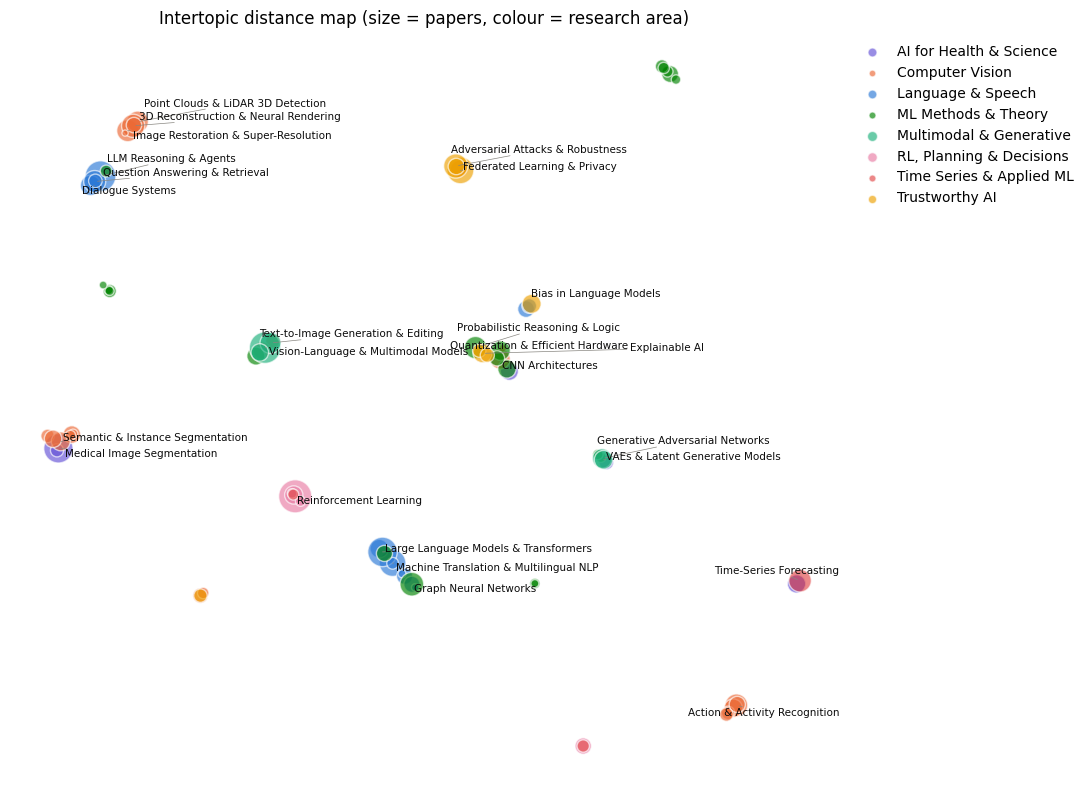

In [19]:
# ---------------------------------------------------------------
# Step 12c: Static, labelled intertopic distance map (report version)
# ---------------------------------------------------------------
# The interactive map shows names only on hover, so for print we redraw it:
# same 2D topic positions, coloured by research area, sized by paper count,
# with the 25 largest topics labelled.
!pip install -q adjustText
from adjustText import adjust_text

AREA_COLORS = dict(zip(RESEARCH_AREAS, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
                                        "#e87ba4", "#008300", "#6250d6", "#e34948"]))

# Re-use the exact coordinates BERTopic computed for the interactive map
d = topic_model.visualize_topics(custom_labels=True).data[0]
pos = pd.DataFrame({"x": d.x, "y": d.y, "topic": [int(c[0]) for c in d.customdata]})
pos["papers"] = pos["topic"].map(full_counts)
pos["area"]   = pos["topic"].map(area_of)

fig, ax = plt.subplots(figsize=(11, 8))
for area, g in pos.groupby("area"):
    ax.scatter(g["x"], g["y"], s=g["papers"] / 25, color=AREA_COLORS[area],
               alpha=0.65, edgecolor="white", linewidth=1, label=area)

texts = [ax.text(r.x, r.y, TOPIC_NAMES[r.topic], fontsize=7.5, color="#0b0b0b")
         for r in pos.nlargest(25, "papers").itertuples()]
adjust_text(texts, ax=ax, arrowprops=dict(arrowstyle="-", color="#898781", lw=0.5))

ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
for s in ax.spines.values(): s.set_visible(False)
ax.set_title("Intertopic distance map (size = papers, colour = research area)")
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left", frameon=False, markerscale=0.4)
plt.tight_layout()
plt.savefig(f"{OUT}/figures/fig2_intertopic_distance_map_labelled.png", dpi=200, bbox_inches="tight")
plt.show()

In [20]:
# ---------------------------------------------------------------
# Step 12d: Topic hierarchy (dendrogram)
# ---------------------------------------------------------------
# Shows how the 85 topics merge into broader groups based on keyword similarity.
fig = topic_model.visualize_hierarchy(custom_labels=True, width=1000, height=1700)
save_plotly(fig, "fig3_topic_hierarchy")

In [21]:
# ---------------------------------------------------------------
# Step 12e: Topic similarity heatmap (appendix figure)
# ---------------------------------------------------------------
# Darker cells = more similar topics (cosine similarity of topic embeddings).
# Topics are ordered into 8 clusters so related topics sit next to each other,
# which makes the block structure (vision / language / ML methods) visible.
fig = topic_model.visualize_heatmap(custom_labels=True, n_clusters=8,
                                    width=1500, height=1500)

# Show every topic name on both axes (Plotly hides every second one by default)
fig.update_xaxes(dtick=1, tickfont_size=8)
fig.update_yaxes(dtick=1, tickfont_size=8)

save_plotly(fig, "figA1_topic_similarity_heatmap")

In [22]:
# ---------------------------------------------------------------
# Step 12f: Top keywords (c-TF-IDF) for the 12 largest topics
# ---------------------------------------------------------------
fig = topic_model.visualize_barchart(top_n_topics=12, n_words=6, custom_labels=True,
                                     width=300, height=280)
save_plotly(fig, "fig4_topic_keywords")

In [23]:
# ---------------------------------------------------------------
# Step 12g: Document map - papers from the balanced sample in 2D
# ---------------------------------------------------------------
# Each dot is a paper coloured by topic; hover shows the paper title.
# The chart reads each paper's topic from the model (all 39k fitting papers),
# so titles and 2D coordinates must cover all of them; `sample` then plots ~20%.
reduced_2d = UMAP(n_neighbors=15, n_components=2, min_dist=0.0,
                  metric="cosine", random_state=SEED).fit_transform(fit_emb)
titles = [d.split(". ")[0] for d in fit_docs]

fig = topic_model.visualize_documents(titles, reduced_embeddings=reduced_2d,
                                      sample=0.2, custom_labels=True,
                                      hide_annotations=True, width=1100, height=800)
save_plotly(fig, "fig5_document_map")

## 10. How research areas and topics changed (2013–2025)
Trends are measured as each topic's **share of that year's papers**, not raw counts. Total AI output grew ~24× over the period, so raw counts make almost every topic look like it is growing.

### Data-quality check: retrospective uploads
In early 2013 arXiv received a bulk upload of past UAI (Uncertainty in AI) conference proceedings dating back to the 1980s. Their first-version date is 2013, but they were written years earlier, which made "Probabilistic Reasoning & Logic" appear to be 29.8% of all 2013 papers (9.2% after the fix). These papers are kept in the topic model (they are genuine AI papers) but **excluded from all time-based analysis**.

In [24]:
# ---------------------------------------------------------------
# Step 13a: Detect retrospective uploads (old papers first posted years later)
# ---------------------------------------------------------------
# 1) Do 2013 papers spike in particular months? (a bulk upload would)
print("2013 papers by month of first submission:")
print(df[df["year"] == 2013]["date"].dt.month.value_counts().sort_index().to_string())

# 2) How many papers mention UAI (Uncertainty in AI conference) in their comments?
mask_uai = df["comments"].str.contains(r"Uncertainty in Artificial Intelligence|\bUAI", case=False, regex=True)
print("\nPapers mentioning UAI, by year:")
print(mask_uai.groupby(df["year"]).sum().to_string())

# 3) General check: comments that mention a year at least 2 years BEFORE first submission
yr_in_comment = df["comments"].str.extract(r"\b((?:19|20)\d{2})\b")[0].astype(float)
old_mention = yr_in_comment <= (df["year"] - 2)
print("\nPapers whose comments cite a year >= 2 years earlier, by year:")
print(old_mention.groupby(df["year"]).sum().to_string())

# 4) Examples from 2013
print("\nExamples:")
print(df.loc[old_mention & (df["year"] == 2013), ["id", "title", "comments"]]
        .head(8).to_string(max_colwidth=70))

2013 papers by month of first submission:
date
1     449
2     392
3     640
4     175
5     167
6     213
7     204
8     135
9     235
10    223
11    222
12    304

Papers mentioning UAI, by year:
year
2013    1027
2014      75
2015      21
2016      15
2017      19
2018      43
2019      50
2020      59
2021      63
2022      64
2023      70
2024      73
2025      63

Papers whose comments cite a year >= 2 years earlier, by year:
year
2013     73
2014     76
2015     84
2016    106
2017    107
2018    145
2019    334
2020    560
2021    583
2022    322
2023    273
2024    241
2025    261

Examples:
            id                                                                  title                                                               comments
5    1301.0173  Knowledge Discovery System For Fiber Reinforced Polymer Matrix Com...  International Journal of Computing, Vol. 2, Issue 7, pp. 121-130,\...
6    1301.0176      Similarity Measuring Approuch for Engineering Materials 

In [25]:
# ---------------------------------------------------------------
# Step 13b: Flag retrospective UAI uploads; build the trend dataset without them
# ---------------------------------------------------------------
# Legacy uploads carry comments like "...Uncertainty in Artificial Intelligence (UAI1993)".
# A paper is flagged if the UAI year in its comments is earlier than its arXiv year.
uai_year = df["comments"].str.extract(r"UAI[\s\-']*((?:19|20)\d{2})", flags=re.IGNORECASE)[0].astype(float)
df["legacy_upload"] = uai_year <= (df["year"] - 1)

print("Flagged legacy uploads by arXiv year:")
print(df.groupby("year")["legacy_upload"].sum().loc[lambda s: s > 0].to_string())
print(f"\n2013: flagged {df.loc[df.year == 2013, 'legacy_upload'].sum()} "
      f"of {mask_uai[df.year == 2013].sum()} papers that mention UAI")
print("\nOriginal UAI years of flagged papers:")
print(uai_year[df["legacy_upload"]].astype(int).value_counts().sort_index().to_string())
print("\nExample flagged comments:")
print(df.loc[df["legacy_upload"], "comments"].head(3).str[:110].to_string())

# Trend dataset = all papers except legacy uploads
dft = df[~df["legacy_upload"]].copy()
papers_per_year = dft.groupby("year").size()
share = (dft.groupby(["topic", "year"]).size().unstack(fill_value=0)
            .div(papers_per_year, axis=1))

print(f"\nPapers used for trend analysis: {len(dft):,} (excluded {df['legacy_upload'].sum():,})")
print(f"'Probabilistic Reasoning & Logic' share in 2013 is now {share.loc[0, 2013]*100:.1f}%")

dft[["id", "year", "topic", "topic_name", "area"]].to_parquet(f"{OUT}/data/paper_topics_trend.parquet", index=False)

Flagged legacy uploads by arXiv year:
year
2013    961
2014     64
2019      1
2020      2
2023      1
2024      4

2013: flagged 961 of 1027 papers that mention UAI

Original UAI years of flagged papers:
0
1985    34
1986    44
1987    49
1988    44
1989    45
1990    65
1991    59
1992    49
1993    65
1994    72
1995    66
1996    63
1997    53
1998    56
1999    74
2000    70
2001    64
2002     3
2003     3
2004     3
2005     2
2007     1
2008     3
2009     8
2010     7
2011     1
2012    10
2013    12
2017     2
2019     1
2022     2
2023     3

Example flagged comments:
52    Appears in Proceedings of the Seventeenth Conference on Uncertainty\n  in Ar...
53    Appears in Proceedings of the Seventeenth Conference on Uncertainty\n  in Ar...
54    Appears in Proceedings of the Seventeenth Conference on Uncertainty\n  in Ar...

Papers used for trend analysis: 377,763 (excluded 1,033)
'Probabilistic Reasoning & Logic' share in 2013 is now 9.2%


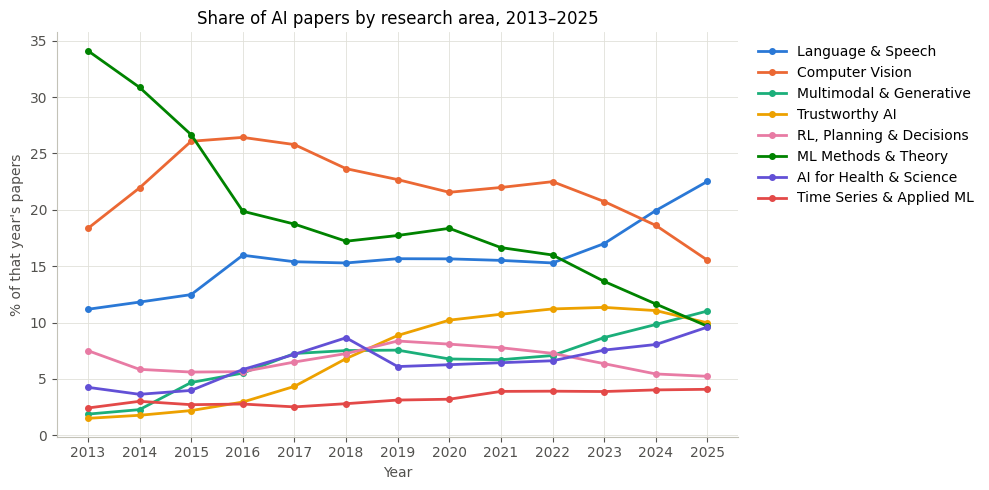

In [26]:
# ---------------------------------------------------------------
# Step 13c: Research-area shares over time
# ---------------------------------------------------------------
import matplotlib as mpl

# Consistent, clean chart style for all report figures
mpl.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e",
    "font.size": 10, "lines.linewidth": 2,
})
# Fixed colour per area (colour follows the area in every chart)
AREA_COLORS = dict(zip(RESEARCH_AREAS, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
                                        "#e87ba4", "#008300", "#6250d6", "#e34948"]))

area_share = (dft[dft["area"] != "Outlier"].groupby(["area", "year"]).size()
              .unstack(fill_value=0).div(papers_per_year, axis=1) * 100)

fig, ax = plt.subplots(figsize=(10, 5))
for area in RESEARCH_AREAS:
    ax.plot(area_share.columns, area_share.loc[area], marker="o", markersize=4,
            color=AREA_COLORS[area], label=area)
ax.set_title("Share of AI papers by research area, 2013–2025")
ax.set_xlabel("Year"); ax.set_ylabel("% of that year's papers")
ax.set_xticks(range(2013, 2026))
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left", frameon=False)
plt.tight_layout()
plt.savefig(f"{OUT}/figures/fig6_area_trends.png", dpi=200, bbox_inches="tight")
plt.show()

area_share.round(1).to_csv(f"{OUT}/results/area_share_by_year.csv")

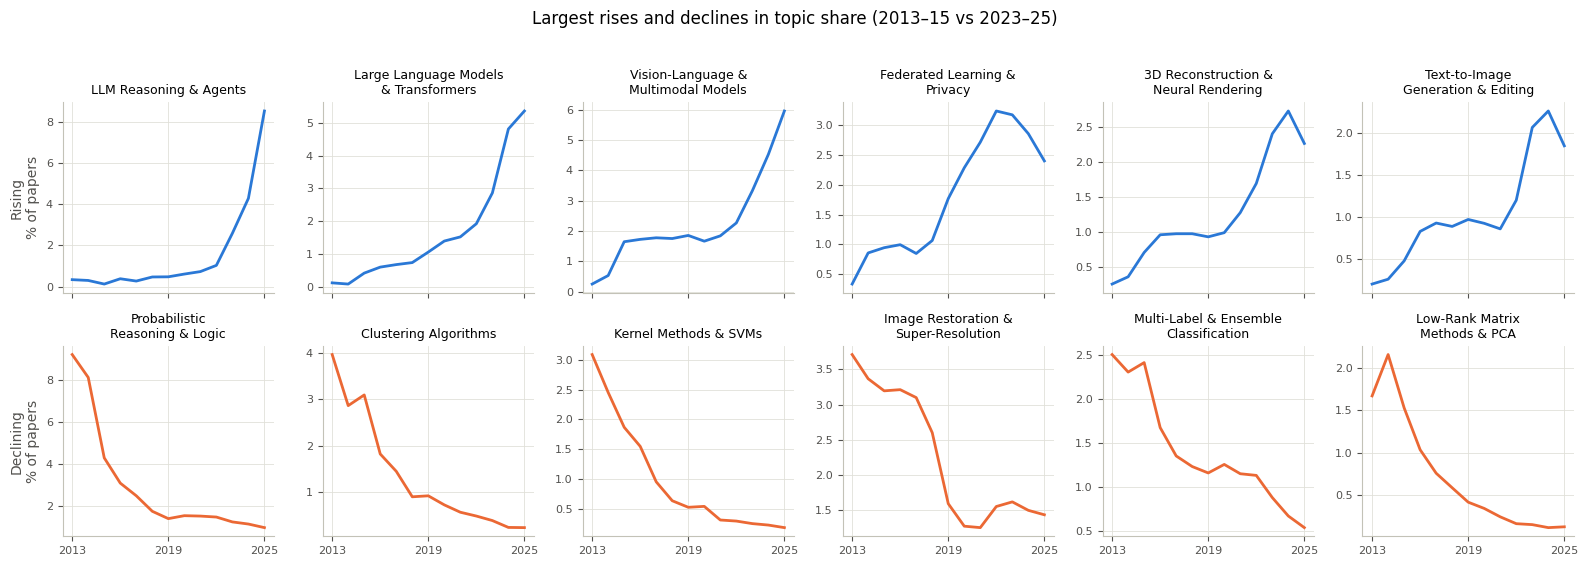

Top 10 risers:
                                       name  share_2013_15_%  share_2023_25_%  change_pp
topic                                                                                   
13                   LLM Reasoning & Agents             0.25             5.13       4.88
18     Large Language Models & Transformers             0.21             4.34       4.13
7       Vision-Language & Multimodal Models             0.81             4.61       3.80
5              Federated Learning & Privacy             0.71             2.81       2.10
26     3D Reconstruction & Neural Rendering             0.44             2.47       2.03
35       Text-to-Image Generation & Editing             0.32             2.05       1.73
24        Point Clouds & LiDAR 3D Detection             0.10             1.76       1.66
8          Adversarial Attacks & Robustness             0.18             1.77       1.60
51                  Bias in Language Models             0.19             1.67       1.49
28    

In [27]:
# ---------------------------------------------------------------
# Step 13d: Topics with the largest rise and fall in share
# ---------------------------------------------------------------
# Change = average share 2023–25 minus average share 2013–15 (percentage points).
# 3-year averages smooth out single-year noise.
topic_share = share.drop(index=-1) * 100            # topic x year, in %
early = topic_share[[2013, 2014, 2015]].mean(axis=1)
late  = topic_share[[2023, 2024, 2025]].mean(axis=1)
change = (late - early).sort_values()

movers = pd.DataFrame({"name": change.index.map(TOPIC_NAMES),
                       "share_2013_15_%": early[change.index].round(2).values,
                       "share_2023_25_%": late[change.index].round(2).values,
                       "change_pp": change.round(2).values}, index=change.index)
movers.to_csv(f"{OUT}/results/table5_topic_change.csv")

risers, decliners = change.index[-6:][::-1], change.index[:6]

# Small multiples: one mini-chart per topic, each with its own y-scale
import textwrap
fig, axes = plt.subplots(2, 6, figsize=(16, 5.5), sharex=True)
for row, (topics_, color, label) in enumerate([(risers, "#2a78d6", "Rising"),
                                               (decliners, "#eb6834", "Declining")]):
    for ax, t in zip(axes[row], topics_):
        ax.plot(topic_share.columns, topic_share.loc[t], color=color)
        ax.set_title("\n".join(textwrap.wrap(TOPIC_NAMES[t], 22)), fontsize=9)
        ax.set_xticks([2013, 2019, 2025])
        ax.tick_params(labelsize=8)
    axes[row][0].set_ylabel(f"{label}\n% of papers")
fig.suptitle("Largest rises and declines in topic share (2013–15 vs 2023–25)", y=1.02)
plt.tight_layout()
plt.savefig(f"{OUT}/figures/fig7_risers_decliners.png", dpi=200, bbox_inches="tight")
plt.show()

print("Top 10 risers:");    print(movers.tail(10)[::-1].to_string())
print("\nTop 10 decliners:"); print(movers.head(10).to_string())

## 11. Forecasting emerging topics
**Question:** using only information available up to year *T*, can we predict whether a topic's share of AI papers will grow by ≥25% over the next two years?

- **Unit of analysis:** one topic at one origin year *T* (2016–2023 labelled; 2024–2025 used for the final forecast).
- **Label:** emerging = 1 if mean share in (T+1, T+2) ≥ 1.25 × mean share in (T−1, T).
- **Features** (all computed from years ≤ T): trend momentum, author dynamics (incl. share of newcomer authors), semantic novelty, and top-venue rate.
- Legacy UAI uploads are excluded; shares use all papers in each year as the denominator.

In [28]:
# ---------------------------------------------------------------
# Step 14: Topic-year panel (counts, shares, authors, venues, embeddings)
# ---------------------------------------------------------------
YEARS  = list(range(2013, 2026))
TOPICS = sorted(t for t in dft["topic"].unique() if t != -1)
tp = dft[dft["topic"] != -1]                       # papers assigned to a real topic

# 1) Paper counts and shares per topic-year (denominator = ALL papers that year)
counts = (tp.groupby(["topic", "year"]).size().unstack(fill_value=0)
            .reindex(index=TOPICS, columns=YEARS, fill_value=0))
shares = counts.div(papers_per_year.reindex(YEARS), axis=1)

# 2) Author sets per topic-year (for newcomer and author-growth features)
ta = tp[["topic", "year", "authors"]].explode("authors").dropna()
ta = ta[ta["authors"].str.len() > 0]
auth_sets = ta.groupby(["topic", "year"])["authors"].agg(set).to_dict()

# 3) Top-venue rate: share of papers whose comments mention a major venue
VENUES = r"\b(?:NeurIPS|NIPS|ICML|ICLR|CVPR|ICCV|ECCV|ACL|EMNLP|NAACL|AAAI|IJCAI|KDD)\b"
venue_flag = tp["comments"].str.contains(VENUES, regex=True)
venue_rate = venue_flag.groupby([tp["topic"], tp["year"]]).mean().to_dict()

# 4) Sum of embeddings per topic-year (for semantic novelty), using numpy for speed
E  = embeddings[tp.index.to_numpy()].astype(np.float32)
ti = tp["topic"].to_numpy()
yi = tp["year"].to_numpy() - 2013
emb_sum = np.zeros((max(TOPICS) + 1, len(YEARS), E.shape[1]), dtype=np.float64)
np.add.at(emb_sum, (ti, yi), E)
emb_n = counts.reindex(index=range(max(TOPICS) + 1), fill_value=0).to_numpy()

print("Panel:", counts.shape, "| total papers in topics:", int(counts.values.sum()))

Panel: (85, 13) | total papers in topics: 334937


In [29]:
# ---------------------------------------------------------------
# Step 15: Features (years <= T only) and labels (years T+1, T+2)
# ---------------------------------------------------------------
EPS = 1e-4                 # avoids log(0) for topics with zero papers in a year
GROWTH_THRESHOLD = 1.25    # "emerging" = share grows by >= 25%
H = 2                      # forecast horizon in years

def share_of(t, y):
    return shares.loc[t, y]

def authors_stats(t, T):
    """Number of authors in year T, and fraction who did not publish in this topic in T-3..T-1."""
    cur  = auth_sets.get((t, T), set())
    prev = set().union(*[auth_sets.get((t, y), set()) for y in range(T - 3, T)])
    n = len(cur)
    return n, (len(cur - prev) / n if n else np.nan)

def novelty(t, T):
    """1 - cosine similarity between the topic's year-T centroid and its T-3..T-1 centroid."""
    n_cur, n_prev = emb_n[t, T - 2013], emb_n[t, T - 2016:T - 2013].sum()
    if n_cur == 0 or n_prev == 0:
        return np.nan
    cur  = emb_sum[t, T - 2013] / n_cur
    prev = emb_sum[t, T - 2016:T - 2013].sum(axis=0) / n_prev
    return 1 - cur @ prev / (np.linalg.norm(cur) * np.linalg.norm(prev))

rows = []
for T in range(2016, 2026):                     # 2016 = first year with 3 years of history
    for t in TOPICS:
        hist = np.log(np.array([share_of(t, y) for y in range(T - 3, T + 1)]) + EPS)  # T-3..T

        n_auth, new_frac = authors_stats(t, T)
        n_auth_prev, _   = authors_stats(t, T - 1)
        first_active = next((y for y in YEARS if counts.loc[t, y] >= 10), None)

        row = {
            "topic": t, "origin": T, "area": area_of[t],
            # --- Trend features ---
            "log_share":     hist[3],
            "growth_1y":     hist[3] - hist[2],
            "growth_3y":     hist[3] - hist[0],
            "slope_4y":      np.polyfit(range(4), hist, 1)[0],
            "acceleration":  (hist[3] - hist[2]) - (hist[2] - hist[1]),
            "topic_age":     (T - first_active) if first_active and first_active <= T else 0,
            # --- Author features ---
            "log_authors":     np.log1p(n_auth),
            "newcomer_frac":   new_frac,
            "author_growth":   np.log1p(n_auth) - np.log1p(n_auth_prev),
            # --- Semantic + venue features ---
            "novelty":         novelty(t, T),
            "venue_rate":      venue_rate.get((t, T), 0.0),
            # --- Baseline scores (same information a simple rule would use) ---
            "past_growth_2y":  np.log((share_of(t, T - 1) + share_of(t, T)) / 2 + EPS)
                             - np.log((share_of(t, T - 3) + share_of(t, T - 2)) / 2 + EPS),
        }

        # --- Label: only defined if the full horizon T+1..T+H is observed ---
        if T + H <= 2025:
            past = (share_of(t, T - 1) + share_of(t, T)) / 2
            fut  = np.mean([share_of(t, y) for y in range(T + 1, T + H + 1)])
            row["future_growth"] = np.log(fut + EPS) - np.log(past + EPS)
            row["emerging"]      = int(fut >= GROWTH_THRESHOLD * past)
        else:
            row["future_growth"], row["emerging"] = np.nan, np.nan
        rows.append(row)

panel = pd.DataFrame(rows)
panel.to_parquet(f"{OUT}/data/forecast_panel.parquet", index=False)

labelled = panel.dropna(subset=["emerging"])
print(f"Rows: {len(panel)} total, {len(labelled)} labelled (origins 2016-2023)")
print("\nShare of 'emerging' labels by origin year:")
print(labelled.groupby("origin")["emerging"].agg(["mean", "sum", "count"]).round(2).to_string())
print("\nMissing values per feature:")
print(panel.isna().sum().loc[lambda s: s > 0].to_string())

Rows: 850 total, 680 labelled (origins 2016-2023)

Share of 'emerging' labels by origin year:
        mean   sum  count
origin                   
2016    0.36  31.0     85
2017    0.32  27.0     85
2018    0.31  26.0     85
2019    0.22  19.0     85
2020    0.16  14.0     85
2021    0.14  12.0     85
2022    0.14  12.0     85
2023    0.14  12.0     85

Missing values per feature:
future_growth    170
emerging         170


### Evaluation protocol
**Rolling-origin evaluation:** for each test year T ∈ {2019,…,2023}, models are trained only on origins ≤ T−2 (whose 2-year outcomes were already observed by year T), then predict all 85 topics at T. This mimics real forecasting and prevents any look-ahead leakage.

**Baselines:** *Persistence* (a topic that grew ≥25% over the past two years keeps growing) and *Trend extrapolation* (extend the recent log-share slope two years ahead).

**Metrics:** ROC-AUC, PR-AUC (informative when positives are rare), F1, Precision@10 (share of each year's top-10 flagged topics that truly emerged), and Spearman correlation with actual growth. 95% confidence intervals from 1,000 bootstrap resamples of topics.

In [30]:
# ---------------------------------------------------------------
# Step 16: Rolling-origin evaluation of baselines and models
# ---------------------------------------------------------------
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score, average_precision_score, f1_score
from scipy.stats import spearmanr

labelled = panel.dropna(subset=["emerging"]).copy()
labelled["emerging"] = labelled["emerging"].astype(int)

FEATURE_GROUPS = {
    "trend":   ["log_share", "growth_1y", "growth_3y", "slope_4y", "acceleration",
                "topic_age", "past_growth_2y"],
    "authors": ["log_authors", "newcomer_frac", "author_growth"],
    "semantic_venue": ["novelty", "venue_rate"],
}
ALL_FEATURES = sum(FEATURE_GROUPS.values(), [])
TEST_YEARS   = range(2019, 2024)
LOG_THR      = np.log(GROWTH_THRESHOLD)
MODELS       = ["Persistence", "Trend extrapolation",
                "Logistic Regression", "Random Forest", "Gradient Boosting"]

def make_models():
    """Fresh, untrained models (small data -> strong regularisation, balanced classes)."""
    return {
        "Logistic Regression": make_pipeline(
            StandardScaler(), LogisticRegression(C=1.0, class_weight="balanced", max_iter=2000)),
        "Random Forest": RandomForestClassifier(
            n_estimators=500, min_samples_leaf=5, class_weight="balanced_subsample",
            random_state=SEED, n_jobs=-1),
        "Gradient Boosting": HistGradientBoostingClassifier(
            max_depth=3, learning_rate=0.05, max_iter=200, l2_regularization=1.0,
            class_weight="balanced", random_state=SEED),
    }

def rolling_predictions(features):
    """Train on origins <= T-H, predict origin T, for every test year T."""
    out = []
    for T in TEST_YEARS:
        train = labelled[labelled["origin"] <= T - H]
        test  = labelled[labelled["origin"] == T]
        pred  = test[["topic", "origin", "emerging", "future_growth"]].copy()
        pred["Persistence"]         = test["past_growth_2y"].values   # baseline scores
        pred["Trend extrapolation"] = test["slope_4y"].values
        for name, model in make_models().items():
            model.fit(train[features], train["emerging"])
            pred[name] = model.predict_proba(test[features])[:, 1]
        out.append(pred)
    return pd.concat(out, ignore_index=True)

def to_label(name, score):
    """Convert scores to yes/no predictions."""
    if name == "Persistence":         return (score >= LOG_THR).astype(int)
    if name == "Trend extrapolation": return (H * score >= LOG_THR).astype(int)
    return (score >= 0.5).astype(int)

def precision_at_k(pred, name, k=10):
    return pred.groupby("origin").apply(lambda g: g.nlargest(k, name)["emerging"].mean()).mean()

preds = rolling_predictions(ALL_FEATURES)
preds.to_csv(f"{OUT}/results/rolling_predictions.csv", index=False)

# ---- Bootstrap over topics for confidence intervals (paired across models) ----
rng = np.random.default_rng(SEED)
idx_by_topic = preds.groupby("topic").indices
topic_ids = np.array(list(idx_by_topic))
y_all = preds["emerging"].to_numpy()
boot = {m: [] for m in MODELS}
for _ in range(1000):
    idx = np.concatenate([idx_by_topic[t] for t in rng.choice(topic_ids, len(topic_ids))])
    for m in MODELS:
        boot[m].append(roc_auc_score(y_all[idx], preds[m].to_numpy()[idx]))
boot = {m: np.array(v) for m, v in boot.items()}

def ci(a):
    return f"[{np.percentile(a, 2.5):.3f}, {np.percentile(a, 97.5):.3f}]"

results = []
for m in MODELS:
    s = preds[m]
    results.append({
        "model": m,
        "ROC-AUC": round(roc_auc_score(y_all, s), 3),
        "AUC 95% CI": ci(boot[m]),
        "PR-AUC": round(average_precision_score(y_all, s), 3),
        "F1": round(f1_score(y_all, to_label(m, s)), 3),
        "Precision@10": round(precision_at_k(preds, m), 3),
        "Spearman": round(spearmanr(s, preds["future_growth"]).correlation, 3),
        "AUC gain vs persistence [95% CI]":
            "-" if m == "Persistence" else
            f"{np.mean(boot[m] - boot['Persistence']):+.3f} {ci(boot[m] - boot['Persistence'])}",
    })
results_df = pd.DataFrame(results)
results_df.to_csv(f"{OUT}/results/table6_forecast_results.csv", index=False)

print(f"Test predictions: {len(preds)} | positive rate: {y_all.mean():.2f} "
      f"(= PR-AUC of a random model)\n")
print(results_df.to_string(index=False))

# ROC-AUC per test year (is performance stable over time?)
print("\nROC-AUC by test year:")
print(preds.groupby("origin").apply(
    lambda g: pd.Series({m: roc_auc_score(g["emerging"], g[m]) for m in MODELS})).round(3).to_string())

Test predictions: 425 | positive rate: 0.16 (= PR-AUC of a random model)

              model  ROC-AUC     AUC 95% CI  PR-AUC    F1  Precision@10  Spearman AUC gain vs persistence [95% CI]
        Persistence    0.852 [0.791, 0.903]   0.523 0.542          0.58     0.656                                -
Trend extrapolation    0.857 [0.799, 0.907]   0.517 0.552          0.56     0.675           +0.005 [-0.003, 0.014]
Logistic Regression    0.882 [0.818, 0.936]   0.698 0.598          0.68     0.593           +0.031 [-0.009, 0.071]
      Random Forest    0.890 [0.837, 0.936]   0.685 0.409          0.68     0.639            +0.038 [0.008, 0.071]
  Gradient Boosting    0.849 [0.778, 0.906]   0.595 0.542          0.60     0.520           -0.003 [-0.043, 0.038]

ROC-AUC by test year:
        Persistence  Trend extrapolation  Logistic Regression  Random Forest  Gradient Boosting
origin                                                                                         
2019          0.852  

### Why do models beat the baselines?
1. **PR-AUC significance**: bootstrap CI for the PR-AUC gain over persistence.
2. **Ablation**: retrain with feature subsets (trend only → + authors → + semantic/venue → all) to see which signals add value beyond momentum.
3. **Permutation importance**: how much PR-AUC drops when each feature is shuffled, averaged over the five test years.

In [31]:
# ---------------------------------------------------------------
# Step 17a: Is the PR-AUC gain over persistence significant?
# ---------------------------------------------------------------
rng = np.random.default_rng(SEED)
boot_ap = {m: [] for m in MODELS}
for _ in range(1000):
    idx = np.concatenate([idx_by_topic[t] for t in rng.choice(topic_ids, len(topic_ids))])
    for m in MODELS:
        boot_ap[m].append(average_precision_score(y_all[idx], preds[m].to_numpy()[idx]))
boot_ap = {m: np.array(v) for m, v in boot_ap.items()}

pr_table = pd.DataFrame([{
    "model": m,
    "PR-AUC": round(average_precision_score(y_all, preds[m]), 3),
    "PR-AUC 95% CI": ci(boot_ap[m]),
    "PR-AUC gain vs persistence [95% CI]": "-" if m == "Persistence" else
        f"{np.mean(boot_ap[m] - boot_ap['Persistence']):+.3f} {ci(boot_ap[m] - boot_ap['Persistence'])}",
} for m in MODELS])
pr_table.to_csv(f"{OUT}/results/table7_prauc_significance.csv", index=False)
print(pr_table.to_string(index=False))

              model  PR-AUC  PR-AUC 95% CI PR-AUC gain vs persistence [95% CI]
        Persistence   0.523 [0.367, 0.683]                                   -
Trend extrapolation   0.517 [0.365, 0.680]              -0.005 [-0.027, 0.016]
Logistic Regression   0.698 [0.525, 0.826]               +0.162 [0.054, 0.263]
      Random Forest   0.685 [0.526, 0.809]               +0.150 [0.051, 0.250]
  Gradient Boosting   0.595 [0.435, 0.741]              +0.064 [-0.045, 0.175]


In [32]:
# ---------------------------------------------------------------
# Step 17b: Feature-group ablation (which signals add value?)
# ---------------------------------------------------------------
ABLATIONS = {
    "Trend only":             FEATURE_GROUPS["trend"],
    "Trend + authors":        FEATURE_GROUPS["trend"] + FEATURE_GROUPS["authors"],
    "Trend + semantic/venue": FEATURE_GROUPS["trend"] + FEATURE_GROUPS["semantic_venue"],
    "All features":           ALL_FEATURES,
}
abl_rows = []
for name, feats in ABLATIONS.items():
    p = rolling_predictions(feats)
    for m in ["Logistic Regression", "Random Forest"]:
        abl_rows.append({"features": name, "model": m,
                         "ROC-AUC": round(roc_auc_score(p["emerging"], p[m]), 3),
                         "PR-AUC": round(average_precision_score(p["emerging"], p[m]), 3),
                         "Precision@10": round(precision_at_k(p, m), 3)})
    print("done:", name)

ablation_df = pd.DataFrame(abl_rows)
ablation_df.to_csv(f"{OUT}/results/table8_ablation.csv", index=False)
print(ablation_df.pivot(index="features", columns="model", values=["ROC-AUC", "PR-AUC"])
                 .loc[list(ABLATIONS)].to_string())

done: Trend only
done: Trend + authors
done: Trend + semantic/venue
done: All features
                                   ROC-AUC                            PR-AUC              
model                  Logistic Regression Random Forest Logistic Regression Random Forest
features                                                                                  
Trend only                           0.837         0.871               0.586         0.641
Trend + authors                      0.847         0.878               0.616         0.650
Trend + semantic/venue               0.874         0.888               0.682         0.688
All features                         0.882         0.890               0.698         0.685


                Logistic Regression  Random Forest  LR coefficient (direction)
growth_1y                    0.0955         0.1363                      1.0788
venue_rate                   0.1738         0.0462                      0.7408
past_growth_2y               0.0334         0.0156                      0.0405
growth_3y                    0.0037         0.0147                     -0.0587
author_growth                0.0669         0.0102                      0.4627
slope_4y                     0.0106         0.0082                      0.1191
novelty                      0.0018         0.0060                      1.4801
log_share                    0.1217         0.0042                     -1.0800
acceleration                 0.0019         0.0031                     -0.3494
topic_age                    0.0057         0.0026                     -0.6371
log_authors                  0.2237        -0.0005                      1.6057
newcomer_frac                0.0456        -0.0109  

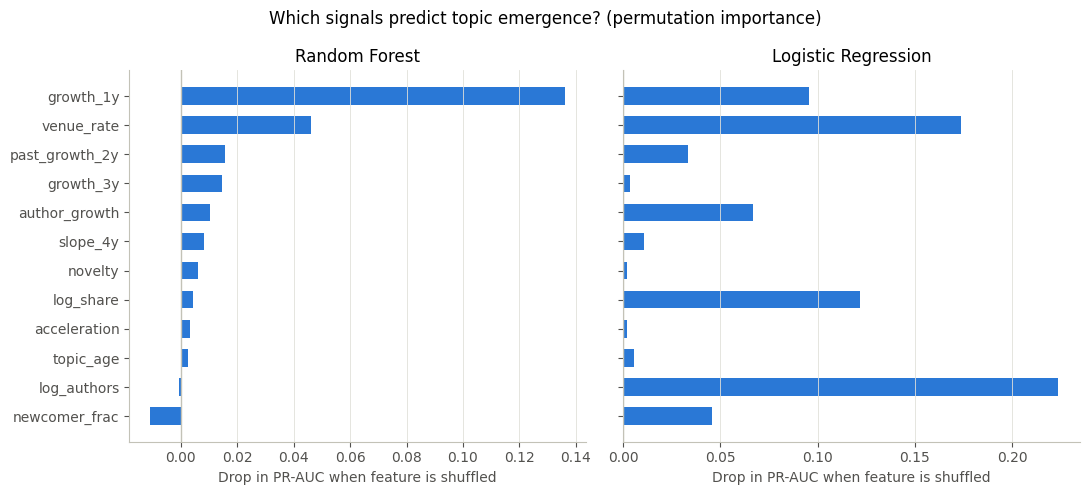

In [33]:
# ---------------------------------------------------------------
# Step 17c: Permutation importance (averaged over the 5 test years)
# ---------------------------------------------------------------
from sklearn.inspection import permutation_importance

imp = {"Logistic Regression": [], "Random Forest": []}
for T in TEST_YEARS:
    train = labelled[labelled["origin"] <= T - H]
    test  = labelled[labelled["origin"] == T]
    models = make_models()
    for m in imp:
        fitted = models[m].fit(train[ALL_FEATURES], train["emerging"])
        r = permutation_importance(fitted, test[ALL_FEATURES], test["emerging"],
                                   scoring="average_precision", n_repeats=20,
                                   random_state=SEED, n_jobs=-1)
        imp[m].append(r.importances_mean)

imp_df = pd.DataFrame({m: np.mean(v, axis=0) for m, v in imp.items()}, index=ALL_FEATURES)

# Direction of each effect: standardised logistic-regression coefficients (all labelled data)
lr_full = make_models()["Logistic Regression"].fit(labelled[ALL_FEATURES], labelled["emerging"])
imp_df["LR coefficient (direction)"] = lr_full[-1].coef_[0]
imp_df.round(4).to_csv(f"{OUT}/results/table9_feature_importance.csv")
print(imp_df.sort_values("Random Forest", ascending=False).round(4).to_string())

# Figure: importance for both models, sorted by Random Forest
order = imp_df.sort_values("Random Forest")["Random Forest"].index
fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharey=True)
for ax, m in zip(axes, ["Random Forest", "Logistic Regression"]):
    ax.barh(order, imp_df.loc[order, m], color="#2a78d6", height=0.6)
    ax.axvline(0, color="#c3c2b7", lw=1)
    ax.set_title(m); ax.set_xlabel("Drop in PR-AUC when feature is shuffled")
    ax.grid(axis="y", visible=False)
fig.suptitle("Which signals predict topic emergence? (permutation importance)")
plt.tight_layout()
plt.savefig(f"{OUT}/figures/fig8_feature_importance.png", dpi=200, bbox_inches="tight")
plt.show()

### Evaluation figures
ROC and precision–recall curves for all models, the gain over the persistence baseline with 95% confidence intervals, stability across test years, the feature-group ablation, and confusion matrices for the best model vs the baseline.

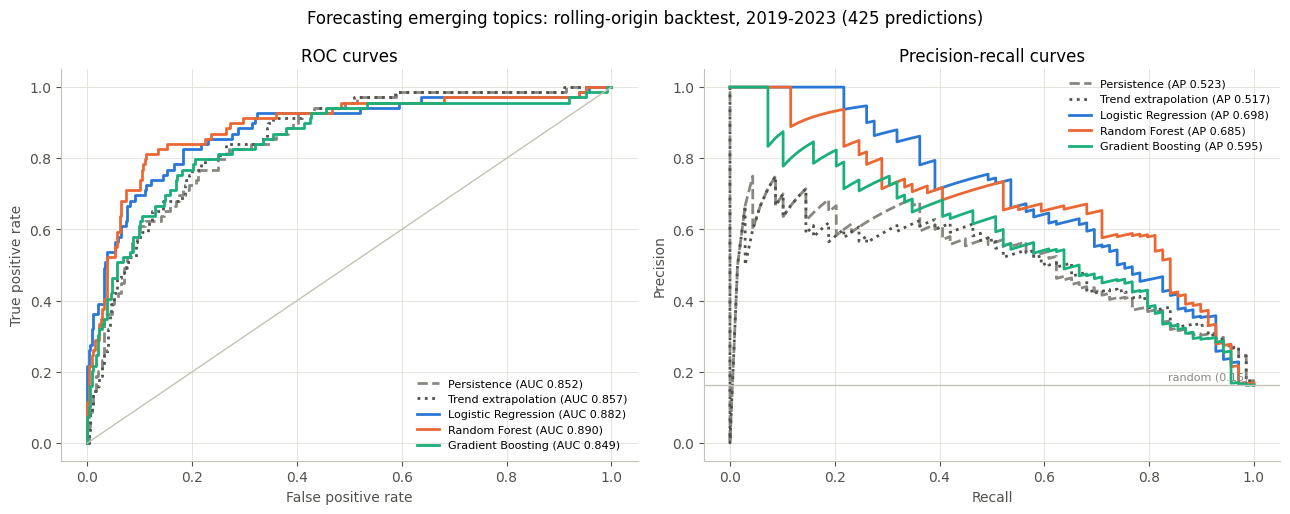

In [34]:
# ---------------------------------------------------------------
# Step 17d: ROC and precision-recall curves (pooled 2019-2023 backtest)
# ---------------------------------------------------------------
from sklearn.metrics import roc_curve, precision_recall_curve

# One fixed style per model, used in every evaluation chart
MODEL_STYLE = {
    "Persistence":         dict(color="#898781", ls="--"),
    "Trend extrapolation": dict(color="#52514e", ls=":"),
    "Logistic Regression": dict(color="#2a78d6", ls="-"),
    "Random Forest":       dict(color="#eb6834", ls="-"),
    "Gradient Boosting":   dict(color="#1baf7a", ls="-"),
}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.2))
for m in MODELS:
    fpr, tpr, _ = roc_curve(y_all, preds[m])
    ax1.plot(fpr, tpr, label=f"{m} (AUC {roc_auc_score(y_all, preds[m]):.3f})", **MODEL_STYLE[m])
    prec, rec, _ = precision_recall_curve(y_all, preds[m])
    ax2.plot(rec, prec, label=f"{m} (AP {average_precision_score(y_all, preds[m]):.3f})", **MODEL_STYLE[m])

ax1.plot([0, 1], [0, 1], color="#c3c2b7", lw=1)                       # random classifier
ax1.set_xlabel("False positive rate"); ax1.set_ylabel("True positive rate")
ax1.set_title("ROC curves")
ax2.axhline(y_all.mean(), color="#c3c2b7", lw=1)                      # random classifier
ax2.text(0.99, y_all.mean() + 0.015, f"random ({y_all.mean():.2f})", ha="right", fontsize=8, color="#898781")
ax2.set_xlabel("Recall"); ax2.set_ylabel("Precision")
ax2.set_title("Precision-recall curves")
ax1.legend(frameon=False, fontsize=8, loc="lower right")
ax2.legend(frameon=False, fontsize=8, loc="upper right")
fig.suptitle("Forecasting emerging topics: rolling-origin backtest, 2019-2023 (425 predictions)")
plt.tight_layout()
plt.savefig(f"{OUT}/figures/fig10_roc_pr_curves.png", dpi=200, bbox_inches="tight")
plt.show()

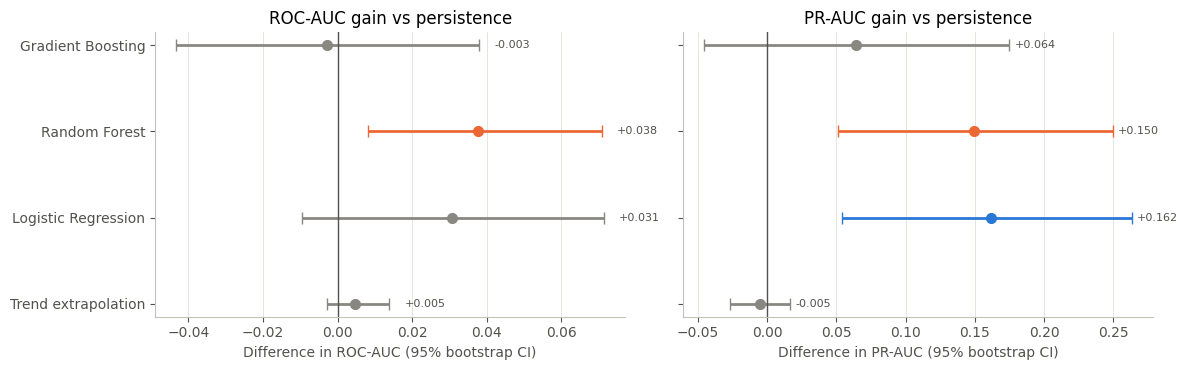

In [35]:
# ---------------------------------------------------------------
# Step 17e: Gain over the persistence baseline with 95% confidence intervals
# ---------------------------------------------------------------
# Coloured = interval excludes zero (significant gain); grey = not significant.
others = [m for m in MODELS if m != "Persistence"]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, (bt, metric) in zip(axes, [(boot, "ROC-AUC"), (boot_ap, "PR-AUC")]):
    for i, m in enumerate(others):
        diff = bt[m] - bt["Persistence"]
        lo, hi = np.percentile(diff, [2.5, 97.5])
        mu = diff.mean()
        col = MODEL_STYLE[m]["color"] if lo > 0 else "#898781"
        ax.errorbar(mu, i, xerr=[[mu - lo], [hi - mu]], fmt="o", color=col,
                    ecolor=col, capsize=4, ms=7, lw=2)
        ax.text(hi + 0.004, i, f"{mu:+.3f}", va="center", fontsize=8, color="#52514e")
    ax.axvline(0, color="#52514e", lw=1)
    ax.set_yticks(range(len(others))); ax.set_yticklabels(others)
    ax.invert_yaxis()
    ax.set_title(f"{metric} gain vs persistence")
    ax.set_xlabel(f"Difference in {metric} (95% bootstrap CI)")
    ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.savefig(f"{OUT}/figures/fig11_gain_vs_baseline.png", dpi=200, bbox_inches="tight")
plt.show()

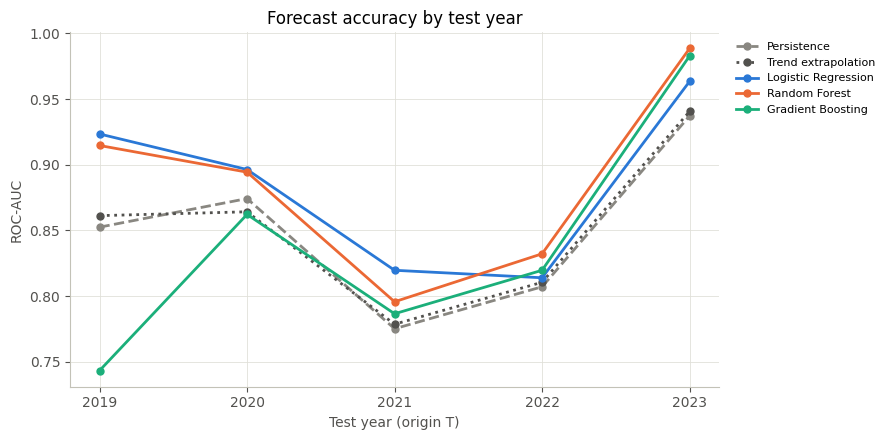

In [36]:
# ---------------------------------------------------------------
# Step 17f: Stability over time - ROC-AUC per test year
# ---------------------------------------------------------------
auc_by_year = preds.groupby("origin").apply(
    lambda g: pd.Series({m: roc_auc_score(g["emerging"], g[m]) for m in MODELS}))

fig, ax = plt.subplots(figsize=(9, 4.5))
for m in MODELS:
    ax.plot(auc_by_year.index, auc_by_year[m], marker="o", markersize=5, label=m, **MODEL_STYLE[m])
ax.set_xticks(list(TEST_YEARS))
ax.set_xlabel("Test year (origin T)"); ax.set_ylabel("ROC-AUC")
ax.set_title("Forecast accuracy by test year")
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left", frameon=False, fontsize=8)
plt.tight_layout()
plt.savefig(f"{OUT}/figures/fig12_auc_by_year.png", dpi=200, bbox_inches="tight")
plt.show()

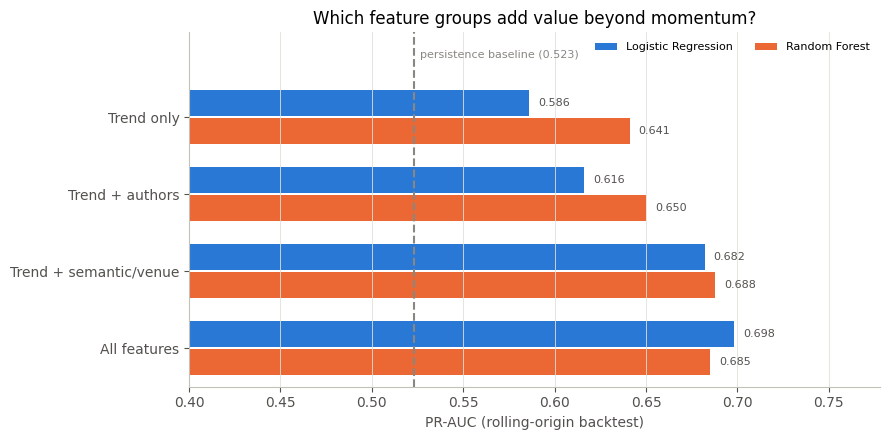

In [37]:
# ---------------------------------------------------------------
# Step 17g: Feature-group ablation chart
# ---------------------------------------------------------------
abl = ablation_df.pivot(index="features", columns="model", values="PR-AUC").loc[list(ABLATIONS)]
baseline_ap = average_precision_score(y_all, preds["Persistence"])

fig, ax = plt.subplots(figsize=(9, 4.5))
y = np.arange(len(abl))
for j, m in enumerate(["Logistic Regression", "Random Forest"]):
    ax.barh(y + (j - 0.5) * 0.36, abl[m], height=0.34, color=MODEL_STYLE[m]["color"], label=m)
    for yi, v in zip(y, abl[m]):
        ax.text(v + 0.005, yi + (j - 0.5) * 0.36, f"{v:.3f}", va="center", fontsize=8, color="#52514e")

# Extra headroom above the first group, used for the baseline label and the legend
ax.set_yticks(y); ax.set_yticklabels(abl.index)
ax.set_ylim(len(abl) - 0.5, -1.1)          # inverted axis: first group at top, space above it

# Persistence baseline as a reference line, labelled inside the headroom
ax.axvline(baseline_ap, color="#898781", ls="--", lw=1.5)
ax.text(baseline_ap + 0.003, -0.8, f"persistence baseline ({baseline_ap:.3f})",
        fontsize=8, color="#898781", va="center")

ax.set_xlabel("PR-AUC (rolling-origin backtest)")
ax.set_title("Which feature groups add value beyond momentum?")
ax.set_xlim(0.4, abl.values.max() + 0.08)
ax.legend(frameon=False, loc="upper right", fontsize=8, ncol=2)
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.savefig(f"{OUT}/figures/fig13_ablation.png", dpi=200, bbox_inches="tight")
plt.show()

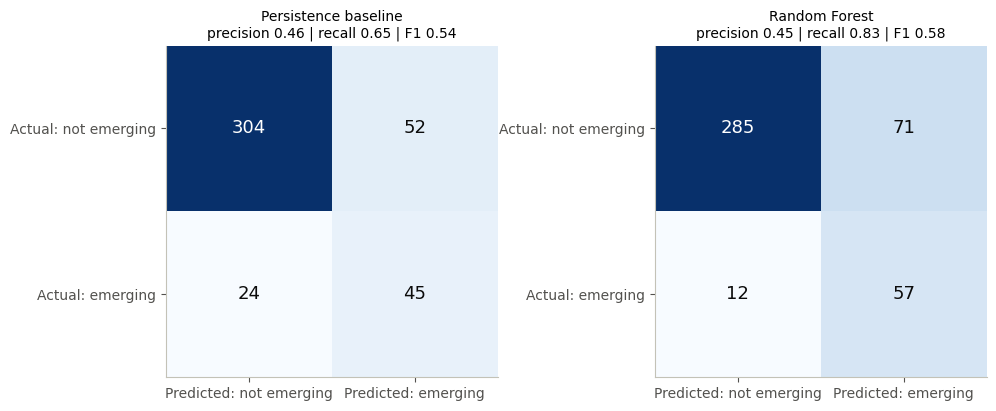

In [38]:
# ---------------------------------------------------------------
# Step 17h: Confusion matrices - Random Forest vs persistence baseline
# ---------------------------------------------------------------
# Random Forest scores are rankings, so each test year we flag as "emerging" the
# same share of topics as the emerging rate seen in that year's TRAINING data
# (no test information is used). Persistence uses its own rule (past growth >= 25%).
from sklearn.metrics import confusion_matrix, precision_score, recall_score

rf_flag = np.zeros(len(preds), dtype=int)
for T in TEST_YEARS:
    train_rate = labelled.loc[labelled["origin"] <= T - H, "emerging"].mean()
    year_rows  = preds.index[preds["origin"] == T]
    k = int(round(train_rate * len(year_rows)))
    rf_flag[preds.loc[year_rows, "Random Forest"].nlargest(k).index] = 1
pers_flag = to_label("Persistence", preds["Persistence"]).to_numpy()

fig, axes = plt.subplots(1, 2, figsize=(10, 4.4))
for ax, (name, flag) in zip(axes, [("Persistence baseline", pers_flag), ("Random Forest", rf_flag)]):
    cm = confusion_matrix(y_all, flag)
    ax.imshow(cm, cmap="Blues")
    for (i, j), v in np.ndenumerate(cm):
        ax.text(j, i, v, ha="center", va="center", fontsize=13,
                color="white" if v > cm.max() / 2 else "#0b0b0b")
    ax.set_xticks([0, 1]); ax.set_xticklabels(["Predicted: not emerging", "Predicted: emerging"])
    ax.set_yticks([0, 1]); ax.set_yticklabels(["Actual: not emerging", "Actual: emerging"])
    ax.set_title(f"{name}\nprecision {precision_score(y_all, flag):.2f} | "
                 f"recall {recall_score(y_all, flag):.2f} | F1 {f1_score(y_all, flag):.2f}", fontsize=10)
    ax.grid(False)
plt.tight_layout()
plt.savefig(f"{OUT}/figures/fig14_confusion_matrices.png", dpi=200, bbox_inches="tight")
plt.show()

## 12. Forecast: which topics are likely to emerge in 2026–27?
Both models are retrained on all labelled origins (2016–2023) and applied to each topic's 2025 features. Scores are used as a **ranking** of emergence likelihood (class-weighted models are not calibrated probabilities). Agreement between the two models is shown as a robustness check.

                                  name                     area  share_2025_%  growth_1y_%  Random Forest  Logistic Regression  rank_LR  both_top15
                LLM Reasoning & Agents        Language & Speech          8.51         99.0          0.881                0.978        1        True
   Vision-Language & Multimodal Models  Multimodal & Generative          5.96         32.0          0.793                0.835        3        True
         Molecular & Drug Discovery ML  AI for Health & Science          1.16         31.0          0.790                0.788        4        True
          Brain Signals & Neuroimaging  AI for Health & Science          0.77         40.0          0.708                0.686        7        True
                General AI & Cognition      ML Methods & Theory          0.52         26.0          0.603                0.667        9        True
            Medical Image Segmentation  AI for Health & Science          3.41         21.0          0.592       

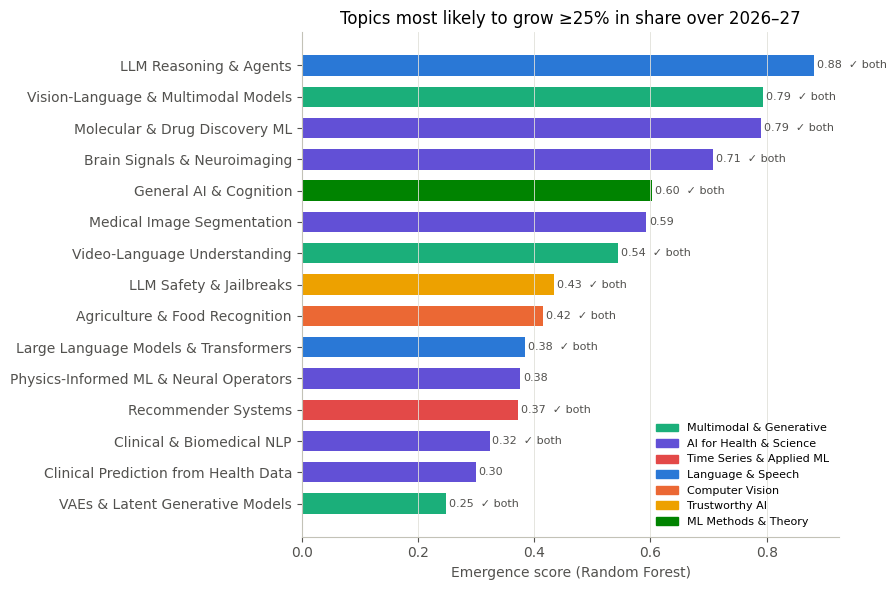

In [39]:
# ---------------------------------------------------------------
# Step 18: Forecast emerging topics for 2026-27 (origin year 2025)
# ---------------------------------------------------------------
X_future = panel[panel["origin"] == 2025].reset_index(drop=True)
models = make_models()

forecast = X_future[["topic"]].copy()
for m in ["Random Forest", "Logistic Regression"]:
    models[m].fit(labelled[ALL_FEATURES], labelled["emerging"])
    forecast[m] = models[m].predict_proba(X_future[ALL_FEATURES])[:, 1]

forecast["name"]           = forecast["topic"].map(TOPIC_NAMES)
forecast["area"]           = forecast["topic"].map(area_of)
forecast["share_2025_%"]   = forecast["topic"].map(shares[2025] * 100).round(2)
forecast["growth_1y_%"]    = ((np.exp(X_future["growth_1y"]) - 1) * 100).round(0)
forecast["rank_RF"]        = forecast["Random Forest"].rank(ascending=False).astype(int)
forecast["rank_LR"]        = forecast["Logistic Regression"].rank(ascending=False).astype(int)
forecast["both_top15"]     = (forecast["rank_RF"] <= 15) & (forecast["rank_LR"] <= 15)

forecast = forecast.sort_values("Random Forest", ascending=False).reset_index(drop=True)
forecast.to_csv(f"{OUT}/results/table10_forecast_2026_27.csv", index=False)

cols = ["name", "area", "share_2025_%", "growth_1y_%", "Random Forest",
        "Logistic Regression", "rank_LR", "both_top15"]
print(forecast[cols].head(15).round(3).to_string(index=False))
print(f"\nTopics in BOTH models' top 15: {forecast['both_top15'].sum()}")

# Figure: top 15 topics by Random Forest score, coloured by research area
top = forecast.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(top["name"], top["Random Forest"], color=top["area"].map(AREA_COLORS), height=0.65)
for y, (score, both) in enumerate(zip(top["Random Forest"], top["both_top15"])):
    ax.text(score + 0.005, y, f"{score:.2f}" + ("  ✓ both" if both else ""),
            va="center", fontsize=8, color="#52514e")
ax.set_xlabel("Emergence score (Random Forest)")
ax.set_title("Topics most likely to grow ≥25% in share over 2026–27")
ax.grid(axis="y", visible=False)
handles = [plt.Rectangle((0, 0), 1, 1, color=AREA_COLORS[a]) for a in top["area"].unique()]
ax.legend(handles, top["area"].unique(), frameon=False, loc="lower right", fontsize=8)
plt.tight_layout()
plt.savefig(f"{OUT}/figures/fig9_forecast_2026_27.png", dpi=200, bbox_inches="tight")
plt.show()

## 13. Out-of-sample validation on unseen 2026 data
The arXiv snapshot extends to October 2026. Papers from **Jan–Sep 2026** were never used in topic modelling, training or tuning. We use them for two checks:
1. **True forecast test (origin 2024):** train only on origins ≤ 2022 (what a forecaster at the end of 2024 could use), predict growth over 2025–26, and compare with what actually happened.
2. **Early check of the 2026–27 forecast:** are the topics flagged in Step 18 already gaining share in 2026?

2026 papers are assigned to the existing 85 topics with the same procedure as the main corpus. Since 2026 is a partial year, we first check that a Jan–Sep share is a reliable estimate of a full-year share (using 2025, where both are known).

In [40]:
# ---------------------------------------------------------------
# Step 19a: Load Jan-Sep 2026 papers (never used anywhere so far)
# ---------------------------------------------------------------
rows26 = []
with open(RAW_JSON) as f:
    for line in tqdm(f, desc="Scanning for 2026 papers"):
        p = json.loads(line)
        cats = p["categories"].split()
        if cats[0] not in AI_CATS:                       # primary category must be AI (as before)
            continue
        if " 2026 " not in p["versions"][0]["created"]:  # quick filter on first-version date
            continue
        rows26.append({"id": p["id"], "title": p["title"], "abstract": p["abstract"],
                       "v1_created": p["versions"][0]["created"],
                       "comments": p.get("comments") or ""})

d26 = pd.DataFrame(rows26)
d26["date"] = pd.to_datetime(d26["v1_created"], format="%a, %d %b %Y %H:%M:%S GMT", errors="coerce")
d26 = d26[(d26["date"].dt.year == 2026) & (d26["date"].dt.month <= 9)]   # complete months only

# Same cleaning rules as the main corpus
d26["title"]    = d26["title"].map(clean)
d26["abstract"] = d26["abstract"].map(clean)
d26 = d26.drop_duplicates("id")
d26 = d26[d26["abstract"].str.split().str.len() >= 30].reset_index(drop=True)
d26["text"] = d26["title"] + ". " + d26["abstract"]

print(f"2026 papers (Jan-Sep, primary AI): {len(d26):,}")
print(d26["date"].dt.month.value_counts().sort_index().to_string())

Scanning for 2026 papers: 0it [00:00, ?it/s]

2026 papers (Jan-Sep, primary AI): 80,775
date
1     7019
2     7700
3     8848
4     8308
5    12105
6     9303
7     7722
8     9007
9    10763


In [41]:
# ---------------------------------------------------------------
# Step 19b: Embed 2026 papers and assign them to the existing 85 topics
# ---------------------------------------------------------------
# Outlier reassignment uses the ORIGINAL topic centroids (mean embedding of each
# topic's papers in the fitting sample), exactly as in Step 9.
centroids = np.vstack([fit_emb[fit_topics == t].mean(axis=0) for t in TOPICS])
centroids /= np.linalg.norm(centroids, axis=1, keepdims=True)

def assign_topics(texts, emb):
    """HDBSCAN assignment, then reassign outliers to the closest centroid if cosine >= 0.6."""
    t, _ = topic_model.transform(texts, emb)
    t = np.array(t)
    out = t == -1
    sims = emb[out] @ centroids.T                       # embeddings are unit length
    best = sims.argmax(axis=1)
    t[np.where(out)[0]] = np.where(sims.max(axis=1) >= OUTLIER_TH,
                                   np.array(TOPICS)[best], -1)
    return t

# Sanity check: re-assigning 5,000 already-assigned 2025 papers should reproduce Step 9
chk = dft[dft["year"] == 2025].sample(5000, random_state=SEED)
chk_t = assign_topics(chk["text"].tolist(), embeddings[chk.index].astype(np.float32))
print(f"Agreement with original assignment on 2025 papers: {np.mean(chk_t == chk['topic'].to_numpy()):.3f}")

# Embeddings for 2026 papers: computed once and reused
EMB26_PATH = f"{OUT}/data/embeddings_2026.npy"
if cached_file("data/embeddings_2026.npy"):
    emb26 = np.load(EMB26_PATH)
    print("[cache] loaded 2026 embeddings")
else:
    encoder = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2", device=device)
    emb26 = encoder.encode(d26["text"].tolist(), batch_size=256, show_progress_bar=True,
                           normalize_embeddings=True).astype(np.float32)
    np.save(EMB26_PATH, emb26)
    del encoder; torch.cuda.empty_cache()
assert len(emb26) == len(d26), "2026 embeddings and papers are misaligned!"

d26["topic"] = assign_topics(d26["text"].tolist(), emb26)
print(f"2026 outlier rate: {np.mean(d26['topic'] == -1):.3f}  (main corpus: 0.113)")
d26[["id", "date", "topic"]].to_parquet(f"{OUT}/data/paper_topics_2026_janSep.parquet", index=False)

2026-10-17 02:47:01,898 - BERTopic - Dimensionality - Reducing dimensionality of input embeddings.
2026-10-17 02:47:04,587 - BERTopic - Dimensionality - Completed ✓
2026-10-17 02:47:04,588 - BERTopic - Clustering - Approximating new points with `hdbscan_model`
2026-10-17 02:47:04,876 - BERTopic - Cluster - Completed ✓


Agreement with original assignment on 2025 papers: 0.960


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Batches:   0%|          | 0/316 [00:00<?, ?it/s]

2026-10-17 02:50:35,974 - BERTopic - Dimensionality - Reducing dimensionality of input embeddings.
2026-10-17 02:51:05,923 - BERTopic - Dimensionality - Completed ✓
2026-10-17 02:51:05,924 - BERTopic - Clustering - Approximating new points with `hdbscan_model`
2026-10-17 02:51:10,551 - BERTopic - Cluster - Completed ✓


2026 outlier rate: 0.181  (main corpus: 0.113)


In [42]:
# ---------------------------------------------------------------
# Step 19c: 2026 topic shares + check that a Jan-Sep share is a fair estimate
# ---------------------------------------------------------------
def topic_shares(frame):
    """Share of the frame's papers in each topic (denominator includes outliers)."""
    return frame[frame["topic"] != -1].groupby("topic").size().reindex(TOPICS, fill_value=0) / len(frame)

share26 = topic_shares(d26)

# Seasonality check on 2025, where both Jan-Sep and full-year shares are known
d25 = dft[dft["year"] == 2025]
s25_full  = topic_shares(d25)
s25_jansep = topic_shares(d25[d25["date"].dt.month <= 9])
rel_diff = (s25_jansep - s25_full).abs() / s25_full
print(f"2025 Jan-Sep vs full-year shares: correlation {np.corrcoef(s25_full, s25_jansep)[0,1]:.4f}, "
      f"median relative difference {rel_diff.median()*100:.1f}%")

# Biggest movers 2025 -> 2026 (for context)
move = pd.DataFrame({"name": [TOPIC_NAMES[t] for t in TOPICS],
                     "share_2025_%": (shares[2025] * 100).round(2).values,
                     "share_2026_JanSep_%": (share26 * 100).round(2).values})
move["change_%"] = ((move["share_2026_JanSep_%"] / move["share_2025_%"] - 1) * 100).round(0)
print("\nFastest-growing topics, 2025 -> 2026:")
print(move.sort_values("change_%", ascending=False).head(8).to_string(index=False))

2025 Jan-Sep vs full-year shares: correlation 0.9991, median relative difference 3.4%

Fastest-growing topics, 2025 -> 2026:
                                   name  share_2025_%  share_2026_JanSep_%  change_%
                 LLM Reasoning & Agents          8.51                11.00      29.0
                    Multi-Armed Bandits          0.77                 0.93      21.0
Learning Theory & Generalization Bounds          0.27                 0.32      19.0
                     Continual Learning          1.01                 1.19      18.0
              Ontologies & Semantic Web          0.11                 0.13      18.0
                 Reinforcement Learning          3.02                 3.49      16.0
           Brain Signals & Neuroimaging          0.77                 0.88      14.0
                LLM Safety & Jailbreaks          1.84                 2.10      14.0


In [43]:
# ---------------------------------------------------------------
# Step 19d: TRUE out-of-sample test - forecast made "at the end of 2024"
# ---------------------------------------------------------------
# Train only on origins <= 2022 (their outcomes were known by 2024).
# Predict origin 2024; outcome = mean share in 2025 and 2026 vs mean share in 2023-24.
test24 = panel[panel["origin"] == 2024].copy().reset_index(drop=True)
past = (shares[2023] + shares[2024]) / 2
fut  = (shares[2025] + share26) / 2
test24["emerging"]      = (fut[test24["topic"]].values >= GROWTH_THRESHOLD * past[test24["topic"]].values).astype(int)
test24["future_growth"] = np.log(fut[test24["topic"]].values + EPS) - np.log(past[test24["topic"]].values + EPS)

train22 = labelled[labelled["origin"] <= 2022]
test24["Persistence"]         = test24["past_growth_2y"]
test24["Trend extrapolation"] = test24["slope_4y"]
for name, model in make_models().items():
    model.fit(train22[ALL_FEATURES], train22["emerging"])
    test24[name] = model.predict_proba(test24[ALL_FEATURES])[:, 1]

y24 = test24["emerging"].to_numpy()
rng = np.random.default_rng(SEED)
boot_idx = [rng.integers(0, len(test24), len(test24)) for _ in range(1000)]

oos = []
for m in MODELS:
    s = test24[m].to_numpy()
    aucs = [roc_auc_score(y24[i], s[i]) for i in boot_idx if 0 < y24[i].sum() < len(i)]
    oos.append({"model": m,
                "ROC-AUC": round(roc_auc_score(y24, s), 3), "AUC 95% CI": ci(np.array(aucs)),
                "PR-AUC": round(average_precision_score(y24, s), 3),
                "Precision@10": round(test24.nlargest(10, m)["emerging"].mean(), 2)})
oos_df = pd.DataFrame(oos)
oos_df.to_csv(f"{OUT}/results/table11_out_of_sample_2024.csv", index=False)

print(f"Topics that actually emerged over 2025-26: {y24.sum()} of {len(y24)} "
      f"(positive rate {y24.mean():.2f} = PR-AUC of a random model)\n")
print(oos_df.to_string(index=False))

print("\nRandom Forest's top-10 picks at the end of 2024, and what happened:")
top10 = test24.nlargest(10, "Random Forest")
print(pd.DataFrame({"topic": top10["topic"].map(TOPIC_NAMES),
                    "score": top10["Random Forest"].round(2),
                    "actual growth %": ((np.exp(top10["future_growth"]) - 1) * 100).round(0),
                    "emerged": top10["emerging"].map({1: "yes", 0: "no"})}).to_string(index=False))

Topics that actually emerged over 2025-26: 8 of 85 (positive rate 0.09 = PR-AUC of a random model)

              model  ROC-AUC     AUC 95% CI  PR-AUC  Precision@10
        Persistence    0.881 [0.660, 0.995]   0.702           0.6
Trend extrapolation    0.914 [0.783, 0.995]   0.697           0.6
Logistic Regression    0.969 [0.927, 0.996]   0.771           0.6
      Random Forest    0.976 [0.932, 1.000]   0.844           0.6
  Gradient Boosting    0.968 [0.919, 1.000]   0.805           0.6

Random Forest's top-10 picks at the end of 2024, and what happened:
                               topic  score  actual growth % emerged
Large Language Models & Transformers   0.89             47.0     yes
             LLM Safety & Jailbreaks   0.87             58.0     yes
 Vision-Language & Multimodal Models   0.82             50.0     yes
              LLM Reasoning & Agents   0.79            184.0     yes
        Video-Language Understanding   0.75             26.0     yes
      Question Answer

In [44]:
# ---------------------------------------------------------------
# Step 19e: Early check of the 2026-27 forecast (preliminary)
# ---------------------------------------------------------------
# The forecast in Step 18 used data up to 2025 only. Are its top-15 topics
# already gaining share in Jan-Sep 2026 compared with the other topics?
fc = forecast.set_index("topic")
fc["growth_2026_%"] = ((share26 / shares[2025]).reindex(fc.index) - 1) * 100
top15 = fc.head(15)
rest  = fc.iloc[15:]

print(f"Median share change 2025 -> Jan-Sep 2026:  top-15 flagged {top15['growth_2026_%'].median():+.0f}%  "
      f"|  other topics {rest['growth_2026_%'].median():+.0f}%")
print(f"Share of topics that grew in 2026:         top-15 flagged {(top15['growth_2026_%'] > 0).mean():.0%}  "
      f"|  other topics {(rest['growth_2026_%'] > 0).mean():.0%}")
print("\n" + top15[["name", "Random Forest", "growth_2026_%"]].round(2).to_string())

Median share change 2025 -> Jan-Sep 2026:  top-15 flagged -2%  |  other topics -18%
Share of topics that grew in 2026:         top-15 flagged 33%  |  other topics 17%

                                         name  Random Forest  growth_2026_%
topic                                                                      
13                     LLM Reasoning & Agents           0.88          29.15
7         Vision-Language & Multimodal Models           0.79          -1.51
58              Molecular & Drug Discovery ML           0.79          -8.98
50               Brain Signals & Neuroimaging           0.71          13.53
44                     General AI & Cognition           0.60         -10.08
2                  Medical Image Segmentation           0.59          -2.26
74               Video-Language Understanding           0.54          -8.09
69                    LLM Safety & Jailbreaks           0.43          14.49
80             Agriculture & Food Recognition           0.42         -31

### Sensitivity check: higher outlier rate in 2026
18.1% of 2026 papers are outliers vs 12.4% in 2025 (11.3% across 2013–2025), which mechanically lowers every topic's 2026 share. We (1) check how much of the gap comes from the assignment procedure itself, and (2) rescale 2026 shares so the share of papers assigned to topics matches 2025, then re-run the out-of-sample evaluation. Conclusions that hold under both versions are robust.

In [45]:
# ---------------------------------------------------------------
# Step 19f: Sensitivity - correct 2026 shares for the higher outlier rate
# ---------------------------------------------------------------
# 1) Does the re-assignment procedure itself produce more outliers? (same 5,000 2025 papers)
print(f"Outlier rate on the same 5,000 papers from 2025: "
      f"original {np.mean(chk['topic'].to_numpy() == -1):.3f} | "
      f"re-assignment procedure {np.mean(chk_t == -1):.3f}")

# 2) Rescale 2026 shares so the fraction of papers assigned to topics matches 2025
out_2025 = np.mean(dft.loc[dft["year"] == 2025, "topic"] == -1)
out_2026 = np.mean(d26["topic"] == -1)
scale = (1 - out_2025) / (1 - out_2026)
share26_adj = share26 * scale
print(f"Outlier rate 2025: {out_2025:.3f} | 2026: {out_2026:.3f} | scale factor for 2026 shares: {scale:.3f}")

# 3) Re-run the out-of-sample test (Step 19d) with adjusted 2026 shares
fut_adj = (shares[2025] + share26_adj) / 2
y_adj = (fut_adj[test24["topic"]].values >= GROWTH_THRESHOLD * past[test24["topic"]].values).astype(int)

rows = []
for m in MODELS:
    s = test24[m].to_numpy()
    rows.append({"model": m,
                 "ROC-AUC (raw)": oos_df.set_index("model").loc[m, "ROC-AUC"],
                 "ROC-AUC (adjusted)": round(roc_auc_score(y_adj, s), 3),
                 "PR-AUC (raw)": oos_df.set_index("model").loc[m, "PR-AUC"],
                 "PR-AUC (adjusted)": round(average_precision_score(y_adj, s), 3),
                 "Precision@10 (adjusted)": round(y_adj[np.argsort(-s)[:10]].mean(), 2)})
sens_df = pd.DataFrame(rows)
sens_df.to_csv(f"{OUT}/results/table12_out_of_sample_sensitivity.csv", index=False)

print(f"\nTopics that emerged over 2025-26: raw {y24.sum()} | adjusted {y_adj.sum()} (of 85)")
changed = test24.loc[y_adj != y24, "topic"].map(TOPIC_NAMES).tolist()
print("Topics whose label changes after adjustment:", changed if changed else "none")
print("\n" + sens_df.to_string(index=False))

# 4) Re-run the early forecast check (Step 19e) with adjusted 2026 shares
g_adj = ((share26_adj / shares[2025]).reindex(fc.index) - 1) * 100
print(f"\nAdjusted median share change 2025 -> 2026:  top-15 flagged {g_adj.iloc[:15].median():+.0f}%  "
      f"|  other topics {g_adj.iloc[15:].median():+.0f}%")
print(f"Adjusted share of topics that grew:        top-15 flagged {(g_adj.iloc[:15] > 0).mean():.0%}  "
      f"|  other topics {(g_adj.iloc[15:] > 0).mean():.0%}")

Outlier rate on the same 5,000 papers from 2025: original 0.120 | re-assignment procedure 0.118
Outlier rate 2025: 0.124 | 2026: 0.181 | scale factor for 2026 shares: 1.070

Topics that emerged over 2025-26: raw 8 | adjusted 9 (of 85)
Topics whose label changes after adjustment: ['Medical Image Segmentation']

              model  ROC-AUC (raw)  ROC-AUC (adjusted)  PR-AUC (raw)  PR-AUC (adjusted)  Precision@10 (adjusted)
        Persistence          0.881               0.889         0.702              0.699                      0.6
Trend extrapolation          0.914               0.918         0.697              0.694                      0.6
Logistic Regression          0.969               0.925         0.771              0.709                      0.6
      Random Forest          0.976               0.966         0.844              0.809                      0.6
  Gradient Boosting          0.968               0.961         0.805              0.778                      0.6

Adjusted 

### What is new in 2026? Clustering the papers that fit no existing topic
The higher 2026 outlier rate is not caused by the assignment procedure (12.0% vs 11.8% on the same 2025 papers), so some 2026 research genuinely falls outside the 85 topics learned from 2013–2025. Clustering these papers reveals candidate *new* topics the forecasting model could not have seen.

In [46]:
# ---------------------------------------------------------------
# Step 19g: Candidate new topics - cluster 2026 papers that fit no existing topic
# ---------------------------------------------------------------
out_mask = d26["topic"].to_numpy() == -1
docs_out = d26.loc[out_mask, "text"].tolist()
emb_out  = emb26[out_mask]
print(f"2026 papers outside all 85 topics: {out_mask.sum():,}")

# Is the outlier share rising through 2026? (a sign of genuinely new content)
print("\nOutlier share by month of 2026 (%):")
print((d26.assign(out=out_mask).groupby(d26["date"].dt.month)["out"].mean() * 100).round(1).to_string())

# Cluster the outliers with the same pipeline (smaller dataset -> smaller min_cluster_size)
new_tm = BERTopic(
    umap_model=UMAP(n_neighbors=15, n_components=5, min_dist=0.0,
                    metric="cosine", random_state=SEED),
    hdbscan_model=HDBSCAN(min_cluster_size=60, min_samples=10, prediction_data=True),
    vectorizer_model=CountVectorizer(stop_words="english", min_df=5),
)
new_topics, _ = new_tm.fit_transform(docs_out, emb_out)

new_info = new_tm.get_topic_info()
new_info = new_info[new_info["Topic"] != -1].head(12).copy()
new_info["keywords"] = new_info["Topic"].map(
    lambda t: ", ".join(w for w, _ in new_tm.get_topic(t)[:7]))
new_info["example_titles"] = new_info["Topic"].map(
    lambda t: " | ".join(d.split(". ")[0][:70] for d in new_tm.get_representative_docs(t)[:2]))
new_info[["Topic", "Count", "keywords", "example_titles"]].to_csv(
    f"{OUT}/results/table13_candidate_new_topics_2026.csv", index=False)

print(f"\nCandidate new clusters found: {len(set(new_topics)) - 1}")
print(new_info[["Count", "keywords", "example_titles"]].to_string(index=False, max_colwidth=90))

2026 papers outside all 85 topics: 14,644

Outlier share by month of 2026 (%):
date
1    14.9
2    14.0
3    14.7
4    16.9
5    17.8
6    18.5
7    20.3
8    21.5
9    22.5

Candidate new clusters found: 42
 Count                                                                      keywords                                                                             example_titles
  1274               diffusion, video, generation, sampling, models, flow, denoising Stream Forcing: Constructing Unified Training Trajectory for Robust St | Causal Motion ...
   781                     scientific, research, review, ai, papers, data, retrieval Scientific Data Skills: Enabling Agent-Ready Scientific Data Services  | ResearchClawBe...
   665           optimization, learning, search, scheduling, energy, framework, edge Multi-Timescale Latent-Action DRL for Joint Optimization in Edge-Cloud | Learning Memor...
   416                          memory, agents, user, retrieval, agent, llm, context Mem

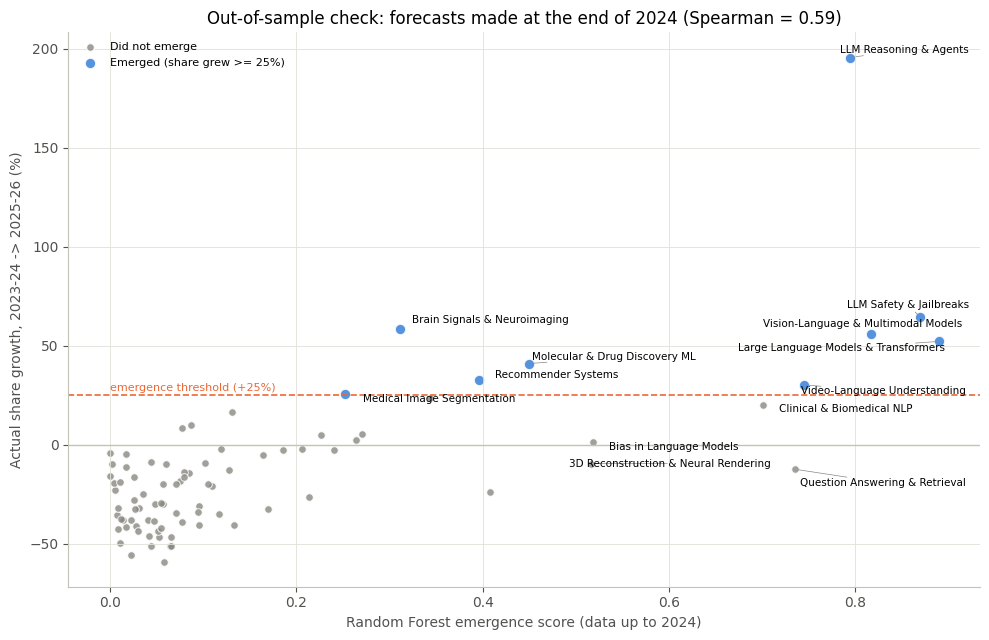

In [47]:
# ---------------------------------------------------------------
# Step 19h: Out-of-sample picture - score at end of 2024 vs actual growth by 2026
# ---------------------------------------------------------------
# Uses the outlier-adjusted 2026 shares (Step 19f).
growth_adj = (fut_adj / past - 1) * 100
sc = test24[["topic", "Random Forest"]].copy()
sc["growth_%"] = sc["topic"].map(growth_adj).values
sc["emerged"]  = y_adj

fig, ax = plt.subplots(figsize=(10, 6.5))
for flag, color, lab, size in [(0, "#898781", "Did not emerge", 30),
                               (1, "#2a78d6", "Emerged (share grew >= 25%)", 55)]:
    g = sc[sc["emerged"] == flag]
    ax.scatter(g["Random Forest"], g["growth_%"], color=color, s=size, alpha=0.8,
               edgecolor="white", linewidth=0.8, label=lab)
ax.axhline(25, color="#eb6834", ls="--", lw=1.2)
ax.text(sc["Random Forest"].min(), 27, "emergence threshold (+25%)", fontsize=8, color="#eb6834")
ax.axhline(0, color="#c3c2b7", lw=1)

# Label the model's top-10 picks and every topic that actually emerged
to_label_ = sc[(sc["Random Forest"].rank(ascending=False) <= 10) | (sc["emerged"] == 1)]
texts = [ax.text(r["Random Forest"], r["growth_%"], TOPIC_NAMES[r["topic"]], fontsize=7.5)
         for _, r in to_label_.iterrows()]
adjust_text(texts, ax=ax, arrowprops=dict(arrowstyle="-", color="#898781", lw=0.5))

rho = spearmanr(sc["Random Forest"], sc["growth_%"]).correlation
ax.set_xlabel("Random Forest emergence score (data up to 2024)")
ax.set_ylabel("Actual share growth, 2023-24 -> 2025-26 (%)")
ax.set_title(f"Out-of-sample check: forecasts made at the end of 2024 (Spearman = {rho:.2f})")
ax.legend(frameon=False, loc="upper left", fontsize=8)
plt.tight_layout()
plt.savefig(f"{OUT}/figures/fig15_out_of_sample_scatter.png", dpi=200, bbox_inches="tight")
plt.show()

**Interpretation (Step 19g):** the share of 2026 papers that fit none of the 85 topics rises from 14.9% in January to 22.5% in September, going up every month from February on, direct evidence that research is moving beyond the 2013–2025 topic structure. Clustering these papers reveals candidate new directions, led by **video diffusion / generative video** (1,274 papers), **AI research agents** (781), **agent memory** (416), **cultural alignment of LLMs** (355), **on-policy distillation** (343), **world models & embodied AI** (275) and **governance of agentic AI** (263). These are candidates from one partial year, not established trends; some may be offshoots of existing topics.

## 14. Key findings

**Data and topics**
- 378,796 primary-AI arXiv papers (2013–2025) were modelled; 1,033 retrospective uploads of past UAI proceedings (mostly 1985–2001, first posted in 2013–14) were detected and excluded from all time-based analysis.
- all-MiniLM-L6-v2 was selected by measurement: highest coherence (NPMI 0.097 vs 0.078 / 0.089) with ~8× faster encoding than MPNet and SPECTER.
- The final BERTopic model has **85 topics** (NPMI 0.130, diversity 0.660). Outlier reassignment cut outliers from 32.5% to 11.3% while *raising* coherence.

**How AI research changed (share of each year's papers)**
- **Language & Speech overtook Computer Vision in 2024** (22.5% vs 15.5% in 2025).
- **ML Methods & Theory fell from 34% (2013) to under 10% (2025)**; Trustworthy AI grew from 1.5% to ~10%.
- **LLM Reasoning & Agents** grew from 0.3% to **8.5%** of all AI papers; kernel methods, clustering and low-rank methods declined steadily.

**Forecasting emerging topics** (growth ≥25% in share over the next two years)
- *Backtest (2019–2023, 425 predictions):* Random Forest ROC-AUC **0.890** vs 0.852 for persistence (gain +0.038, 95% CI [0.008, 0.071]); PR-AUC **0.685 vs 0.523** (gain +0.150, CI [0.051, 0.250]); Precision@10 0.68 vs 0.58.
- *Ablation:* the semantic/venue signals added the most beyond momentum (LR PR-AUC 0.586 → 0.682); the share of newcomer authors helped little.
- *True out-of-sample test (forecast made with data to 2024, checked on 2025 + unseen 2026):* Random Forest PR-AUC **0.844** (0.809 after correcting for 2026 outliers) vs 0.70 for persistence; 6 of its top-10 picks emerged. Logistic Regression's advantage did not survive the correction, so **Random Forest is the recommended model**.
- *Forecast for 2026–27:* LLM Reasoning & Agents, Vision-Language models, Molecular & Drug Discovery ML and Brain Signals & Neuroimaging lead; 6 of the top 15 are in AI for Health & Science. Early evidence (Jan–Sep 2026, adjusted): flagged topics changed **+5%** in share vs **−13%** for other topics, and **67% vs 27%** of them grew.

## 15. Limitations and future work

**Limitations**
- **Metadata only:** titles and abstracts, no full text or citations. The venue signal depends on authors mentioning the venue in arXiv comments, a habit that differs between communities.
- **arXiv coverage:** not all AI research is posted to arXiv; journals and some industry work are under-represented.
- **Fixed topic set:** the 85 topics were learned from 2013–2025. The rising 2026 outlier share shows new research cannot be captured until the model is refitted, so entirely new topics cannot be forecast before they exist.
- **Definition of "emerging":** ≥25% growth in *share* over two years is one reasonable choice; other thresholds or horizons could change individual labels. A topic can lose share while its paper count still grows.
- **Small sample for supervised learning:** 85 topics × 8 origins = 680 labelled rows, so confidence intervals are wide; the out-of-sample test has only 8–9 positive topics.
- **Hard cases:** topics that rise and then plateau (e.g. QA & Retrieval, 3D Neural Rendering) are the main source of errors. Models rank emergence well but correlate less with growth *size* than simple baselines (Spearman 0.64 vs 0.68).
- **Other choices:** topic names were assigned manually (checked against keywords and titles); random-forest scores are rankings, not calibrated probabilities; only the UAI bulk upload was removed, and a small trickle of late-posted older papers (at most about 2% of papers in any year) remains.

**Future work**
- Refit the topic model periodically (or use dynamic topic models) to absorb new research directions.
- Add citation signals (e.g. OpenAlex) and test other thresholds and horizons.
- Calibrate model probabilities, and model rise-and-plateau dynamics explicitly.
- Track the candidate 2026 clusters to see which become established topics.